# Métricas de la red de dinastías: Mundo, Asia y Europa

**CD.30 Redes Complejas · Maestría en Ciencia de Datos · ITBA**

Analizamos la red genealógica de nobles y gobernantes (siglos VI a XV) construida a partir de Wikidata. Cada nodo es una persona y cada arista un vínculo familiar (progenitor, cónyuge o hermano). Todas las medidas se calculan para **tres redes**:

- **Mundo**: la red completa.
- **Asia** y **Europa**: los subgrafos inducidos por la columna `continente` (sólo las personas de ese continente y los vínculos entre ellas).

## 0. Instalación y librerías

In [ ]:
%pip install -q networkx pandas numpy matplotlib scipy plotly ipywidgets

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import ipywidgets as widgets
import scipy
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

SEMILLA = 72                      # para que los resultados aleatorios sean reproducibles
REGIONES = ["Mundo", "Asia", "Europa"]
COLORES = {"Mundo": "tab:gray", "Asia": "tab:red", "Europa": "tab:blue"}
plt.rcParams["figure.dpi"] = 110

for nombre_mod, modulo in [("networkx", nx), ("pandas", pd), ("numpy", np), ("scipy", scipy), ("ipywidgets", widgets)]:
    print(f"{nombre_mod:11s}", modulo.__version__)

networkx    3.6.1
pandas      2.3.3
numpy       2.3.4
scipy       1.16.3
ipywidgets  8.1.9


## 1. Los datos

La red fue construida con consultas a https://query.wikidata.org/sparql y luego limpiada. Usamos los archivos de `csv-finales/`:

- `nodos_finales_completos.csv`: una fila por persona (`Id` de Wikidata, `Label`, `casa`, `anio`, `continente`, ...).
- `relaciones_limpias.csv`: una fila por vínculo (`Source`, `Target`, `Label` = tipo de vínculo, `Weight`, `sospechosa`).

In [3]:
# Busca la carpeta de datos tanto si el notebook corre desde colabs-analisis/ como desde la raíz del repo (o Colab)
CANDIDATAS = [Path("../csv-finales"), Path("csv-finales"), Path(".")]
CARPETA_DATOS = next(p for p in CANDIDATAS if (p / "nodos_finales_completos.csv").exists())

def cargar_datos():
    nodos = pd.read_csv(CARPETA_DATOS / "nodos_finales_completos.csv")
    relaciones = pd.read_csv(CARPETA_DATOS / "relaciones_limpias.csv")
    return nodos, relaciones

nodos, relaciones = cargar_datos()
print("Carpeta de datos:", CARPETA_DATOS.resolve())
print("Dinastías:", len(nodos), "personas,", len(relaciones), "relaciones")
print()
print(nodos["continente"].value_counts().to_string())
nodos.head()

Carpeta de datos: C:\Users\HP\Tomas\Ciencia de datos\2do año\Redes Complejas\Redes-Complejas\csv-finales
Dinastías: 18060 personas, 46782 relaciones

continente
Europa    13785
Asia       4275


,Id,Label,casa,titulo,anio,anio_estimado,anio_original,ubicacion,ubicacion_estimada,anio_impreciso,sexo_inferido,n_padres,n_madres,n_hijos,n_conyuges,n_hermanos,sospechoso,casa_original,continente
0,Q7419,Emperador Yangdi,dinastía Sui,NaN,569,False,569.0,Chang'an,False,False,M,1,1,4,11,9,False,dinastía Sui,Asia
1,Q9458,Mahoma,Banu Háshim,NaN,571,False,571.0,La Meca,False,False,M,0,0,2,12,0,False,Banu Háshim,Asia
2,Q39619,Ali Ibn Abi Talib,NaN,príncipe de los creyentes,599,False,599.0,La Meca,False,False,NaN,0,0,0,7,8,False,príncipe de los creyentes,Asia
3,Q22968293,Samson,NaN,príncipe franco,573,False,573.0,NaN,False,False,NaN,1,1,0,0,10,False,príncipe franco,Europa
4,Q22968296,Dagobert,NaN,príncipe franco,580,False,580.0,NaN,False,False,NaN,1,1,0,0,10,False,príncipe franco,Europa


Antes de construir un grafo conviene **mirar los datos**: ¿qué tipos de vínculo hay?, ¿son dirigidos?, ¿qué significa el peso?

In [4]:
print(relaciones.groupby(["Label", "Type"])["Weight"].agg(["count", "min", "max"]))
print()
print("Relaciones sospechosas:", relaciones["sospechosa"].sum())
print(relaciones.loc[relaciones["sospechosa"], "motivo"].value_counts().to_string())

pares = pd.DataFrame(np.sort(relaciones[["Source", "Target"]].values, axis=1), columns=["u", "v"])
print("\nPares de personas con más de un vínculo registrado:", pares.duplicated().sum())
print("Ids repetidos:", nodos["Id"].duplicated().sum(), "   Labels (nombres) repetidos:", nodos["Label"].duplicated().sum())

                    count  min  max
Label   Type                       
conyuge Undirected   7079    2    2
hermano Undirected  23744    1    1
madre   Directed     6927    3    3
padre   Directed     9032    3    3

Relaciones sospechosas: 26
motivo
par contradictorio: progenitor+hermano    17
par contradictorio: progenitor+conyuge     5
progenitor con rol padre y madre           4

Pares de personas con más de un vínculo registrado: 22
Ids repetidos: 0    Labels (nombres) repetidos: 770


Observaciones que condicionan cómo armamos el grafo:

- El **peso** codifica el tipo de vínculo: hermano = 1, cónyuge = 2, padre/madre = 3. Un peso mayor es un vínculo más fuerte. Para caminos con pesos usamos la **distancia** $1/w$ (un vínculo fuerte es un paso "corto").
- Los vínculos padre/madre son **dirigidos** (`Source` es el hijo, `Target` el progenitor). Para las métricas usamos la red **no dirigida**; en la sección 2.3 miramos la versión dirigida.
- Hay unos pocos pares con dos vínculos a la vez (por ejemplo progenitor y hermano, marcados como `sospechosa`). Un `nx.Graph` admite una sola arista por par: nos quedamos con el peso máximo y guardamos todos los tipos en el atributo `tipo`.
- Hay **nombres repetidos**: para identificar a alguien sin ambigüedad usamos el `Id` de Wikidata.

## 2. Redes y grafos

### 2.1 Construir los grafos

Armamos la red del **Mundo** con todos los nodos y aristas, y de ella sacamos los subgrafos inducidos de **Asia** y **Europa**. Las aristas que unen personas de continentes distintos sólo están en la red del Mundo.

In [5]:
EXCLUIR_SOSPECHOSAS = False       # ✏️ pongan True para descartar las relaciones marcadas como sospechosas

def construir_grafo(nodos, relaciones):
    rel = relaciones[~relaciones["sospechosa"]] if EXCLUIR_SOSPECHOSAS else relaciones
    rel = rel.assign(u=np.sort(rel[["Source", "Target"]].values, axis=1)[:, 0],
                     v=np.sort(rel[["Source", "Target"]].values, axis=1)[:, 1])
    aristas = (rel.groupby(["u", "v"])
                  .agg(weight=("Weight", "max"),
                       tipo=("Label", lambda s: "+".join(sorted(set(s)))),
                       sospechosa=("sospechosa", "any"))
                  .reset_index())
    aristas["distancia"] = 1 / aristas["weight"]

    G = nx.from_pandas_edgelist(aristas, source="u", target="v",
                                edge_attr=["weight", "distancia", "tipo", "sospechosa"], create_using=nx.Graph)
    G.add_nodes_from(nodos["Id"])                      # personas sin vínculos también son nodos
    atributos = {
        "label": nodos["Label"],
        "casa": nodos["casa"].fillna(""),
        "titulo": nodos["titulo"].fillna(""),
        "continente": nodos["continente"],
        "anio": nodos["anio"].astype(int),
        "sexo": nodos["sexo_inferido"].fillna("?"),
    }
    for attr, col in atributos.items():
        nx.set_node_attributes(G, dict(zip(nodos["Id"], col)), name=attr)
    return G

def inducido(G, seleccion):
    # Subgrafo inducido que conserva el orden de los nodos de G. G.subgraph() recorre los nodos en el
    # orden de un set, que cambia en cada ejecución, y eso vuelve no reproducibles los resultados con semilla.
    seleccion = set(seleccion)
    H = G.__class__()
    H.add_nodes_from((v, d) for v, d in G.nodes(data=True) if v in seleccion)
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if u in seleccion and v in seleccion)
    return H

def subred(G, continente):
    return inducido(G, [v for v, c in G.nodes(data="continente") if c == continente])

mundo = construir_grafo(nodos, relaciones)
redes = {"Mundo": mundo, "Asia": subred(mundo, "Asia"), "Europa": subred(mundo, "Europa")}

for region, G in redes.items():
    print(f"{region:7s} {G}")
intercontinentales = sum(1 for u, v in mundo.edges() if mundo.nodes[u]["continente"] != mundo.nodes[v]["continente"])
print(f"\nAristas entre personas de distinto continente (sólo en Mundo): {intercontinentales}")

Mundo   Graph with 18060 nodes and 46760 edges
Asia    Graph with 4275 nodes and 14728 edges
Europa  Graph with 13785 nodes and 31197 edges

Aristas entre personas de distinto continente (sólo en Mundo): 835


Funciones auxiliares para pasar de nombres a `Id` y viceversa. `resolver` acepta un `Id` o un nombre exacto; si el nombre está repetido avisa y muestra los candidatos.

In [6]:
def nombre(G, v):
    return G.nodes[v]["label"]

def buscar(G, texto, n=15):
    # Personas cuyo nombre contiene el texto (sin distinguir mayúsculas)
    texto = texto.lower()
    return sorted((G.nodes[v]["label"], v) for v in G if texto in G.nodes[v]["label"].lower())[:n]

def resolver(G, nombre_o_id):
    # Devuelve el Id de una persona a partir de su Id o de su nombre exacto
    if nombre_o_id in G:
        return nombre_o_id
    texto = nombre_o_id.strip().lower()
    ids = [v for v in G if G.nodes[v]["label"].lower() == texto]
    if len(ids) == 1:
        return ids[0]
    if len(ids) > 1:
        raise ValueError(f"'{nombre_o_id}' es ambiguo, usen el Id: "
                         f"{[(v, G.nodes[v]['casa'], G.nodes[v]['anio']) for v in ids]}")
    raise ValueError(f"No encontré a '{nombre_o_id}'. ¿Será alguno de estos? {buscar(G, nombre_o_id.split()[0])}")

def gigante(G):
    # Componente conexa más grande, como grafo independiente
    return inducido(G, max(nx.connected_components(G), key=len))

print(buscar(mundo, "Capeto"))
print(resolver(mundo, "Carlomagno"), resolver(mundo, "Q720"), nombre(mundo, "Q720"))

[('Hugo Capeto', 'Q159575')]
Q3044 Q720 Gengis Kan


### 2.2 Tres formas de representar la misma red

Tomemos un subgrafo chico, **Hugo Capeto** y sus familiares directos, y veámoslo como **lista de aristas**, **lista de adyacencia** y **matriz de adyacencia**.

In [7]:
centro_familia = resolver(mundo, "Hugo Capeto")
familia = [centro_familia] + sorted(mundo.neighbors(centro_familia), key=lambda v: mundo.nodes[v]["anio"])
S = mundo.subgraph(familia)
cortos = [nombre(mundo, v)[:22] for v in familia]

print("Lista de aristas (con tipo y peso):")
for u, v, d in S.edges(data=True):
    print(f"  {nombre(S, u)} — {nombre(S, v)}   {d['tipo']}, peso {d['weight']}")

print("\nLista de adyacencia:")
for v in familia:
    print(f"  {nombre(S, v)}: {[nombre(S, w) for w in S.neighbors(v)]}")

Lista de aristas (con tipo y peso):
  Hedwige de Sajonia — Hugo Capeto   madre, peso 3
  Hedwige de Sajonia — Beatriz de Francia   madre, peso 3
  Hedwige de Sajonia — Emma de Francia   madre, peso 3
  Hedwige de Sajonia — Hugo el Grande   conyuge, peso 2
  Hedwige de Sajonia — Enrique I de Borgoña   madre, peso 3
  Hedwige de Sajonia — Otón Enrique de Borgoña   madre, peso 3
  Roberto II de Francia — Hugo Capeto   padre, peso 3
  Roberto II de Francia — Adelaida de Aquitania   madre, peso 3
  Beatriz de Francia — Hugo Capeto   hermano, peso 1
  Beatriz de Francia — Emma de Francia   hermano, peso 1
  Beatriz de Francia — Heribert d'Auxerre   hermano, peso 1
  Beatriz de Francia — Hugo el Grande   padre, peso 3
  Beatriz de Francia — Enrique I de Borgoña   hermano, peso 1
  Beatriz de Francia — Otón Enrique de Borgoña   hermano, peso 1
  Otón Enrique de Borgoña — Hugo Capeto   hermano, peso 1
  Otón Enrique de Borgoña — Emma de Francia   hermano, peso 1
  Otón Enrique de Borgoña — Heri

Matriz de adyacencia (sin pesos):


,Hugo Capeto,Hugo el Grande,Hedwige de Sajonia,Beatriz de Francia,Emma de Francia,Heribert d'Auxerre,Otón Enrique de Borgoñ,Enrique I de Borgoña,Adelaida de Aquitania,Roberto II de Francia
Hugo Capeto,0,1,1,1,1,1,1,1,1,1
Hugo el Grande,1,0,1,1,1,0,1,1,0,0
Hedwige de Sajonia,1,1,0,1,1,0,1,1,0,0
Beatriz de Francia,1,1,1,0,1,1,1,1,0,0
Emma de Francia,1,1,1,1,0,1,1,1,0,0
Heribert d'Auxerre,1,0,0,1,1,0,1,1,0,0
Otón Enrique de Borgoñ,1,1,1,1,1,1,0,1,0,0
Enrique I de Borgoña,1,1,1,1,1,1,1,0,0,0
Adelaida de Aquitania,1,0,0,0,0,0,0,0,0,1
Roberto II de Francia,1,0,0,0,0,0,0,0,1,0


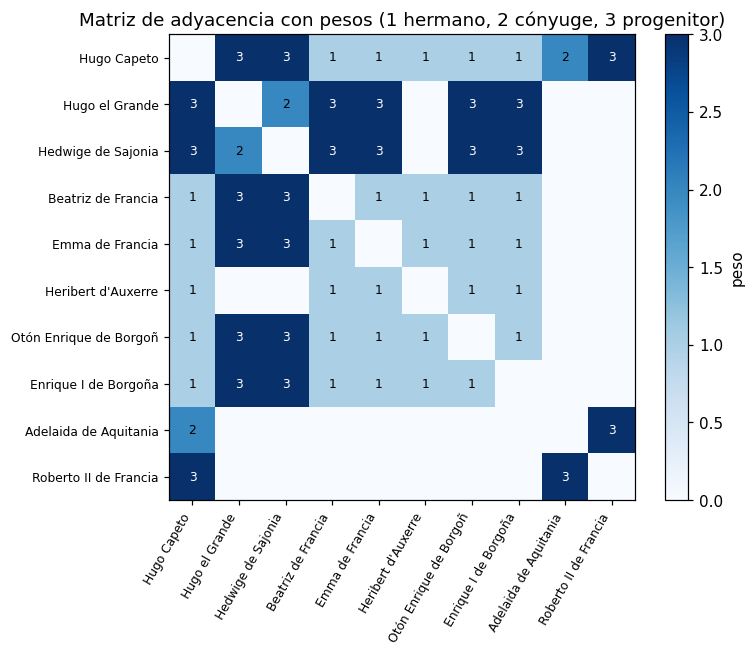

In [8]:
A = nx.to_pandas_adjacency(S, nodelist=familia, weight=None, dtype=int)      # 1 si hay arista, 0 si no
W = nx.to_pandas_adjacency(S, nodelist=familia, weight="weight", dtype=int)  # con pesos
A.index = A.columns = cortos

print("Matriz de adyacencia (sin pesos):")
display(A)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(W.values, cmap="Blues", vmin=0, vmax=3)
ax.set_xticks(range(len(familia)), cortos, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(familia)), cortos, fontsize=8)
for i in range(len(familia)):
    for j in range(len(familia)):
        if W.values[i, j] > 0:
            ax.text(j, i, W.values[i, j], ha="center", va="center", fontsize=8,
                    color="white" if W.values[i, j] > 2 else "black")
ax.set_title("Matriz de adyacencia con pesos (1 hermano, 2 cónyuge, 3 progenitor)")
plt.colorbar(im, ax=ax, label="peso")
plt.show()

Observen que:

- La matriz es **simétrica** ($A_{ij} = A_{ji}$) porque la red es no dirigida, y la diagonal es cero porque no hay *self-loops*.
- Sumando una fila de la matriz sin pesos se obtiene el **grado** de la persona; sumando una fila de la matriz con pesos, su **fuerza**.
- En la red completa la matriz sería de $18060 \times 18060$ y casi toda ceros: las redes reales son **ralas**. Por eso networkx la guarda como lista de adyacencia.

In [9]:
print("Grados desde la matriz:", A.sum(axis=1).to_dict())
print()
for region, G in redes.items():
    N, L = G.number_of_nodes(), G.number_of_edges()
    print(f"{region:7s}: {L} aristas de {N*(N-1)//2:,} posibles. Densidad = {nx.density(G):.6f}")

Grados desde la matriz: {'Hugo Capeto': 9, 'Hugo el Grande': 6, 'Hedwige de Sajonia': 6, 'Beatriz de Francia': 7, 'Emma de Francia': 7, "Heribert d'Auxerre": 5, 'Otón Enrique de Borgoñ': 7, 'Enrique I de Borgoña': 7, 'Adelaida de Aquitania': 2, 'Roberto II de Francia': 2}

Mundo  : 46760 aristas de 163,072,770 posibles. Densidad = 0.000287
Asia   : 14728 aristas de 9,135,675 posibles. Densidad = 0.001612
Europa : 31197 aristas de 95,006,220 posibles. Densidad = 0.000328


### 2.3 La red dirigida: el árbol genealógico

Si nos quedamos sólo con los vínculos padre/madre y respetamos su dirección (hijo → progenitor), obtenemos un grafo **dirigido**. El grado de salida de una persona es cuántos progenitores tiene registrados (0, 1 o 2) y el de entrada, cuántos hijos. Como nadie puede ser su propio antepasado, debería ser un grafo **acíclico** (DAG); y el camino dirigido más largo es la cadena de generaciones más larga registrada.

In [10]:
def genealogia(nodos, relaciones, continente=None):
    rel = relaciones[relaciones["Type"] == "Directed"]
    D = nx.from_pandas_edgelist(rel, "Source", "Target", create_using=nx.DiGraph)   # hijo → progenitor
    D.add_nodes_from(nodos["Id"])
    nx.set_node_attributes(D, dict(zip(nodos["Id"], nodos["Label"])), "label")
    nx.set_node_attributes(D, dict(zip(nodos["Id"], nodos["anio"])), "anio")
    if continente is not None:
        D = inducido(D, nodos.loc[nodos["continente"] == continente, "Id"])
    return D

for region in REGIONES:
    D = genealogia(nodos, relaciones, None if region == "Mundo" else region)
    salida, entrada = dict(D.out_degree()), dict(D.in_degree())
    print(f"--- {region}: {D.number_of_edges()} vínculos hijo → progenitor")
    print(f"  ¿Acíclico?: {nx.is_directed_acyclic_graph(D)}")
    print(f"  Personas sin progenitores registrados: {sum(1 for k in salida.values() if k == 0)} de {len(salida)}")
    mas_hijos = max(entrada, key=entrada.get)
    print(f"  Más hijos registrados: {D.nodes[mas_hijos]['label']} ({entrada[mas_hijos]})")
    linea = nx.dag_longest_path(D)                       # va del descendiente al antepasado
    print(f"  Línea genealógica más larga: {len(linea)} generaciones, "
          f"de {D.nodes[linea[-1]]['label']} ({D.nodes[linea[-1]]['anio']}) "
          f"a {D.nodes[linea[0]]['label']} ({D.nodes[linea[0]]['anio']})")

--- Mundo: 15957 vínculos hijo → progenitor
  ¿Acíclico?: True
  Personas sin progenitores registrados: 8896 de 18060
  Más hijos registrados: Song Huizong (68)
  Línea genealógica más larga: 32 generaciones, de Itta (588) a Henry VII of Waldeck-Waldeck (1400)


--- Asia: 2554 vínculos hijo → progenitor
  ¿Acíclico?: True
  Personas sin progenitores registrados: 2580 de 4275
  Más hijos registrados: Song Huizong (68)
  Línea genealógica más larga: 26 generaciones, de Shiki no miko (666) a Emperador Sukō (1334)


--- Europa: 13020 vínculos hijo → progenitor
  ¿Acíclico?: True
  Personas sin progenitores registrados: 6443 de 13785
  Más hijos registrados: Haroldo I de Noruega (21)
  Línea genealógica más larga: 32 generaciones, de Itta (588) a Henry VII of Waldeck-Waldeck (1400)


## 3. Distribución de grados

In [11]:
def resumen(G):
    k = np.array([d for _, d in G.degree()])
    comps = sorted((len(c) for c in nx.connected_components(G)), reverse=True)
    return {"nodos": G.number_of_nodes(), "aristas": G.number_of_edges(),
            "suma de grados": k.sum(), "2L": 2 * G.number_of_edges(),
            "<k>": k.mean(), "k máximo": k.max(), "aislados": int((k == 0).sum()),
            "componentes": len(comps), "tamaño gigante": comps[0], "fracción gigante": comps[0] / len(k)}

pd.DataFrame({region: resumen(G) for region, G in redes.items()}).round(3)

,Mundo,Asia,Europa
nodos,18060.000,4275.000,13785.000
aristas,46760.000,14728.000,31197.000
suma de grados,93520.000,29456.000,62394.000
2L,93520.000,29456.000,62394.000
<k>,5.178,6.890,4.526
k máximo,100.000,100.000,32.000
aislados,52.000,42.000,54.000
componentes,74.000,110.000,80.000
tamaño gigante,15242.000,1362.000,13578.000
fracción gigante,0.844,0.319,0.985


**Ojo con Asia.** Europa es casi toda una única componente, pero Asia está partida en varias familias grandes sin vínculos registrados entre sí (la familia imperial japonesa, los Tang, los Song, los gengiskánidas, ...). Su "componente gigante" tiene menos de un tercio de las personas, así que las medidas que se calculan sobre la gigante (distancias, centralidades) en Asia describen sobre todo a una sola de esas familias. En la red del Mundo, en cambio, parte de Asia (por ejemplo, los mongoles) queda unida a Europa por matrimonios.

¿Qué tipo de vínculo aporta más al grado? Contamos, para cada persona, cuántos vínculos de cada tipo tiene (una arista con dos tipos cuenta en ambos).

In [12]:
from collections import Counter

def grado_por_tipo(G):
    cuenta = {tipo: Counter() for tipo in ["hermano", "conyuge", "padre", "madre"]}
    for u, v, t in G.edges(data="tipo"):
        for tipo in t.split("+"):
            cuenta[tipo][u] += 1
            cuenta[tipo][v] += 1
    return pd.DataFrame(cuenta, index=list(G)).fillna(0)

pd.DataFrame({region: grado_por_tipo(G).mean() for region, G in redes.items()}).round(2).rename_axis("vínculos promedio")

,Mundo,Asia,Europa
vínculos promedio,,,
hermano,2.63,5.01,1.85
conyuge,0.78,0.70,0.79
padre,1.00,0.78,1.04
madre,0.77,0.42,0.85


In [13]:
def tabla_top(G, n=10):
    df = pd.DataFrame({"persona": [nombre(G, v) for v in G],
                       "grado": [G.degree(v) for v in G],
                       "fuerza": [G.degree(v, weight="weight") for v in G]})
    return df.sort_values(["grado", "fuerza"], ascending=False).head(n).reset_index(drop=True)

pd.concat({region: tabla_top(G) for region, G in redes.items()}, axis=1)

Mundo                          Asia               \
           persona grado fuerza          persona grado fuerza   
0     Song Huizong   100    247     Song Huizong   100    247   
1     Song Gaozong    78     93     Song Gaozong    78     93   
2          Qinzong    75     88          Qinzong    75     88   
3        Li Shimin    74    135        Li Shimin    74    135   
4          Su Zong    71    104          Su Zong    71    104   
5        Ande Diji    71     76        Ande Diji    71     76   
6   Princess Cheng    71     76   Princess Cheng    71     76   
7  Princess Yanguo    71     76  Princess Yanguo    71     76   
8       Maode Diji    71     76       Maode Diji    71     76   
9       Jiade-diji    71     76       Jiade-diji    71     76   

                            Europa               
                           persona grado fuerza  
0               Erico I de Noruega    32     53  
1                     Ludovico Pío    30     54  
2             Haroldo I de Noruega    29     80  
3                       Carlomagno    27     64  
4  Alfonso X de Castilla y de León    27     56  
5         Fernando III de Castilla    25     55  
6               Leonor Plantagenet    25     50  
7                  Ring Haraldsson    25     32  
8                    Bjørn Farmann    25     31  
9            Rogelio II de Sicilia    24     43

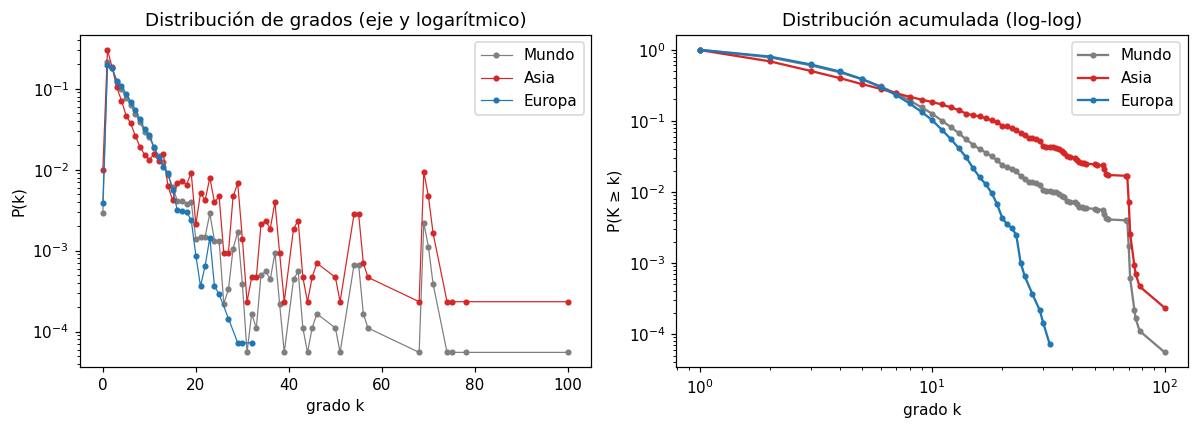

In [14]:
def pk(G):
    k = np.array([d for _, d in G.degree()])
    valores, cuentas = np.unique(k, return_counts=True)
    return valores, cuentas / len(k)

def ccdf(G):
    k = np.array([d for _, d in G.degree()])
    valores = np.unique(k)
    return valores, np.array([(k >= v).mean() for v in valores])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for region, G in redes.items():
    x, y = pk(G)
    ax[0].semilogy(x, y, "o-", ms=3, lw=0.8, label=region, color=COLORES[region])
    x, y = ccdf(G)
    ax[1].loglog(x[x > 0], y[x > 0], "o-", ms=3, label=region, color=COLORES[region])
ax[0].set(xlabel="grado k", ylabel="P(k)", title="Distribución de grados (eje y logarítmico)")
ax[1].set(xlabel="grado k", ylabel="P(K ≥ k)", title="Distribución acumulada (log-log)")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()

La mayoría de las personas tiene pocos vínculos registrados y unas pocas tienen decenas: la distribución es muy asimétrica y el grado medio no representa a una persona "típica". A esos nodos de grado muy alto se los llama **hubs**. Comparen la cola de Asia con la de Europa.

¿Las personas con más vínculos son también las de mayor fuerza? Como el peso depende del tipo de vínculo, la fuerza distingue a quien tiene muchos hijos (peso 3) de quien tiene muchos hermanos (peso 1).

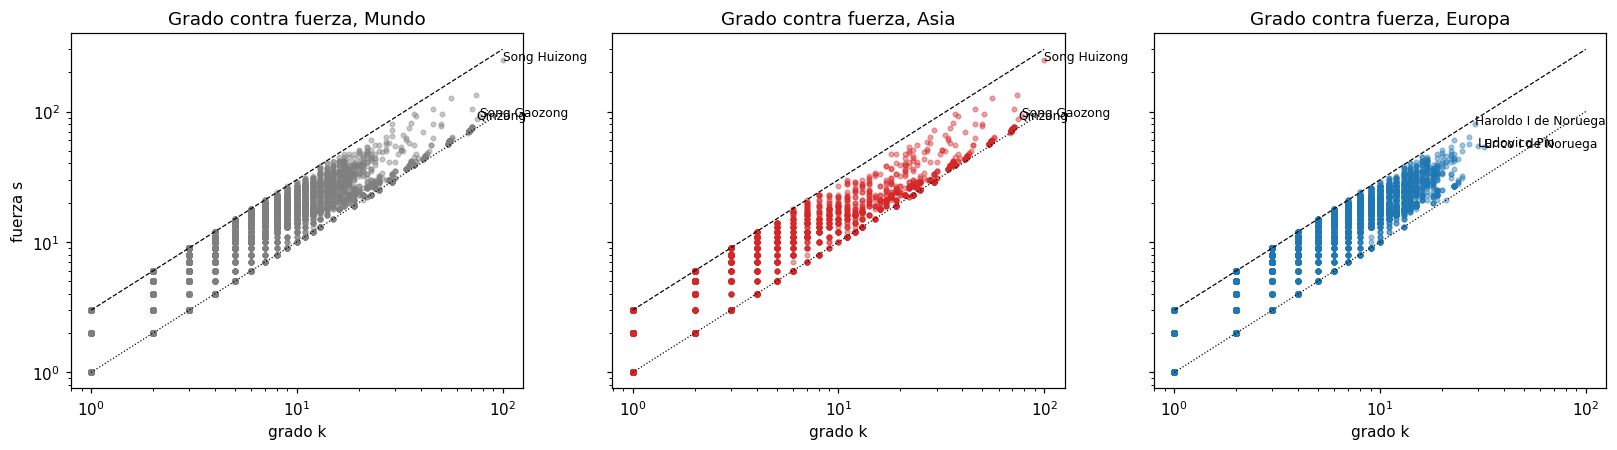

In [15]:
def grado_fuerza(G, nombre_o_id):
    v = resolver(G, nombre_o_id)
    return G.degree(v), G.degree(v, weight="weight")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for ax, (region, G) in zip(axs, redes.items()):
    k = np.array([G.degree(v) for v in G])
    s = np.array([G.degree(v, weight="weight") for v in G])
    ax.loglog(k[k > 0], s[k > 0], "o", ms=3, alpha=0.4, color=COLORES[region])
    ax.loglog([1, 100], [1, 100], "k:", lw=0.8)       # sólo hermanos
    ax.loglog([1, 100], [3, 300], "k--", lw=0.8)      # sólo hijos/progenitores
    for v in sorted(G, key=G.degree, reverse=True)[:3]:
        ax.annotate(nombre(G, v), grado_fuerza(G, v), fontsize=8)
    ax.set(xlabel="grado k", title=f"Grado contra fuerza, {region}")
axs[0].set_ylabel("fuerza s")
plt.tight_layout(); plt.show()

La línea punteada ($s = k$) corresponde a alguien con sólo vínculos de hermano y la discontinua ($s = 3k$) a alguien con sólo vínculos padre/madre.

## 4. Visualizaciones

Para dibujar una red hay que decidir dónde va cada nodo: eso lo hace un **layout**. No hay un dibujo "correcto"; cada layout destaca cosas distintas. Probemos cuatro:

- **spring** (Fruchterman–Reingold): las aristas son resortes y los nodos se repelen. Los grupos muy conectados quedan juntos.
- **Kamada–Kawai**: busca que la distancia en el dibujo sea proporcional a la distancia en la red.
- **espectral**: usa autovectores del laplaciano de la red como coordenadas.
- **circular**: pone los nodos en un círculo, sin mirar la estructura.

**Ojo con el tamaño.** Con más de 15.000 nodos, el layout spring de networkx tarda más de un minuto *por iteración*, y Kamada–Kawai necesita todas las distancias entre pares. Por eso dibujamos un **núcleo** de cada red: las `TAMANO_NUCLEO` personas más cercanas (en la red) a una persona central de su componente gigante. La red completa la exploramos en Gephi (sección 11).

In [16]:
TAMANO_NUCLEO = 600        # ✏️ más grande = dibujo más completo pero más lento

def nucleo(G, n=TAMANO_NUCLEO):
    # Las n personas más cercanas a la de mayor betweenness (aproximada) de la componente gigante
    Gg = gigante(G)
    bet = nx.betweenness_centrality(Gg, k=min(100, len(Gg)), seed=SEMILLA)
    centro = max(bet, key=bet.get)
    cercanos = list(nx.single_source_shortest_path_length(Gg, centro))[:n]   # orden BFS = por distancia
    return inducido(Gg, cercanos), centro

def calcular_layouts(G):
    return {"spring": nx.spring_layout(G, k=0.15, iterations=100, seed=SEMILLA),
            "Kamada–Kawai": nx.kamada_kawai_layout(G),
            "espectral": nx.spectral_layout(G),
            "circular": nx.circular_layout(G)}

nucleos, layouts = {}, {}
for region, G in redes.items():
    nucleos[region], centro = nucleo(G)
    layouts[region] = calcular_layouts(nucleos[region])
    print(f"{region:7s} núcleo de {nucleos[region].number_of_nodes()} personas alrededor de {nombre(G, centro)}")

Mundo   núcleo de 600 personas alrededor de Abaqa


Asia    núcleo de 600 personas alrededor de Emperador Kōkō


Europa  núcleo de 600 personas alrededor de Juan I de Portugal


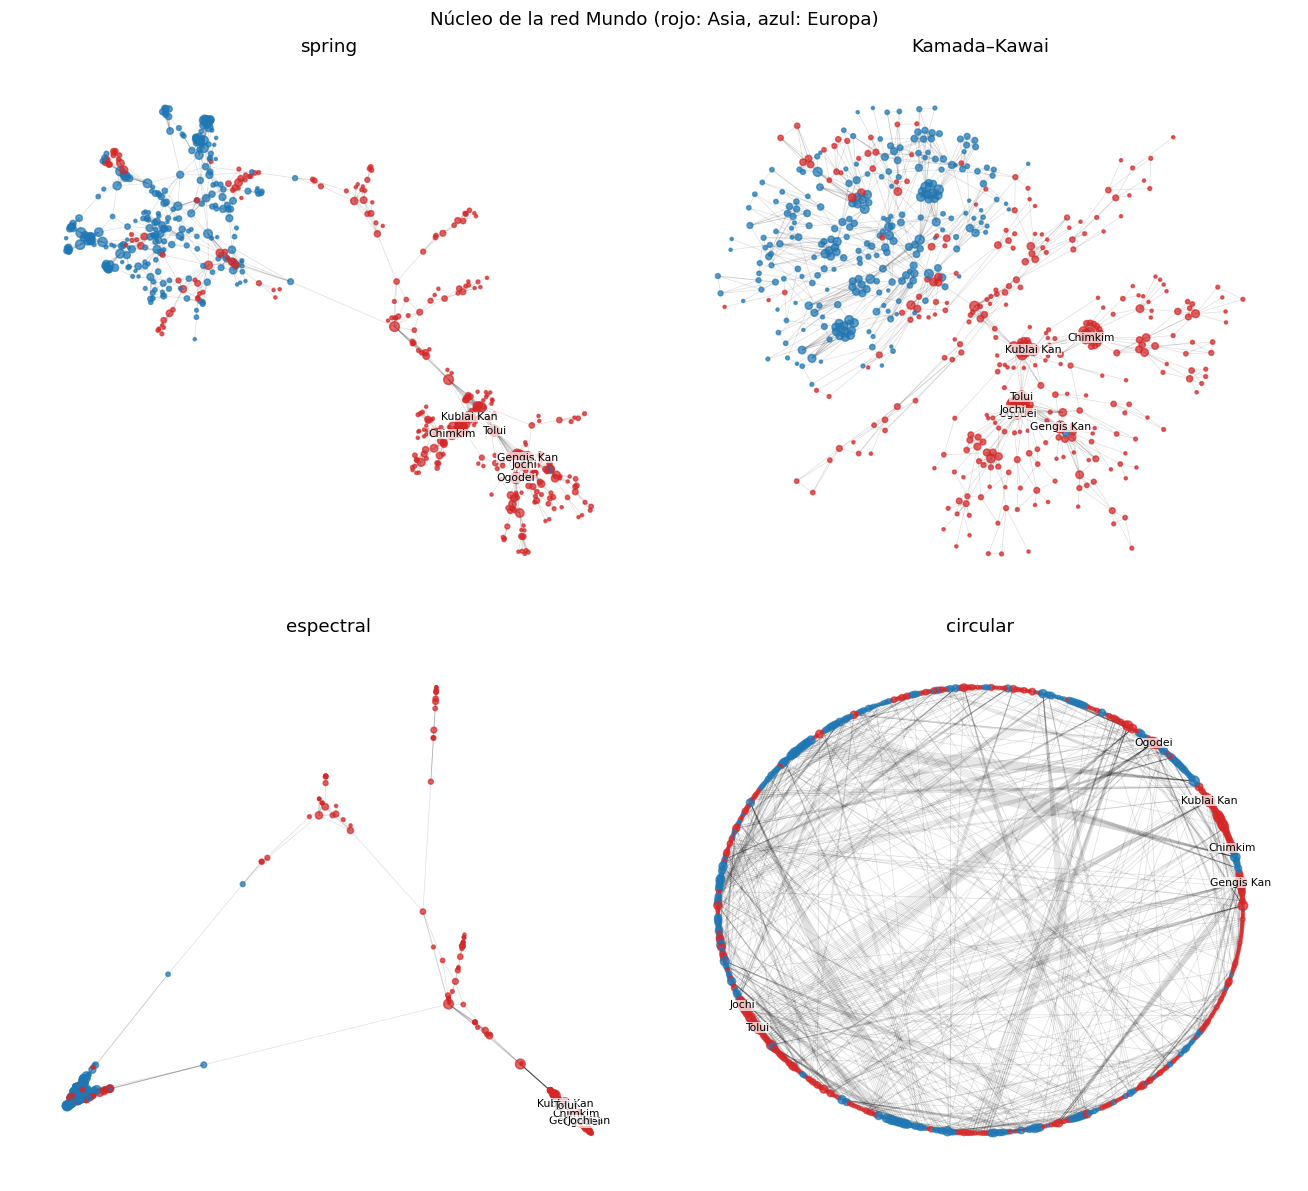

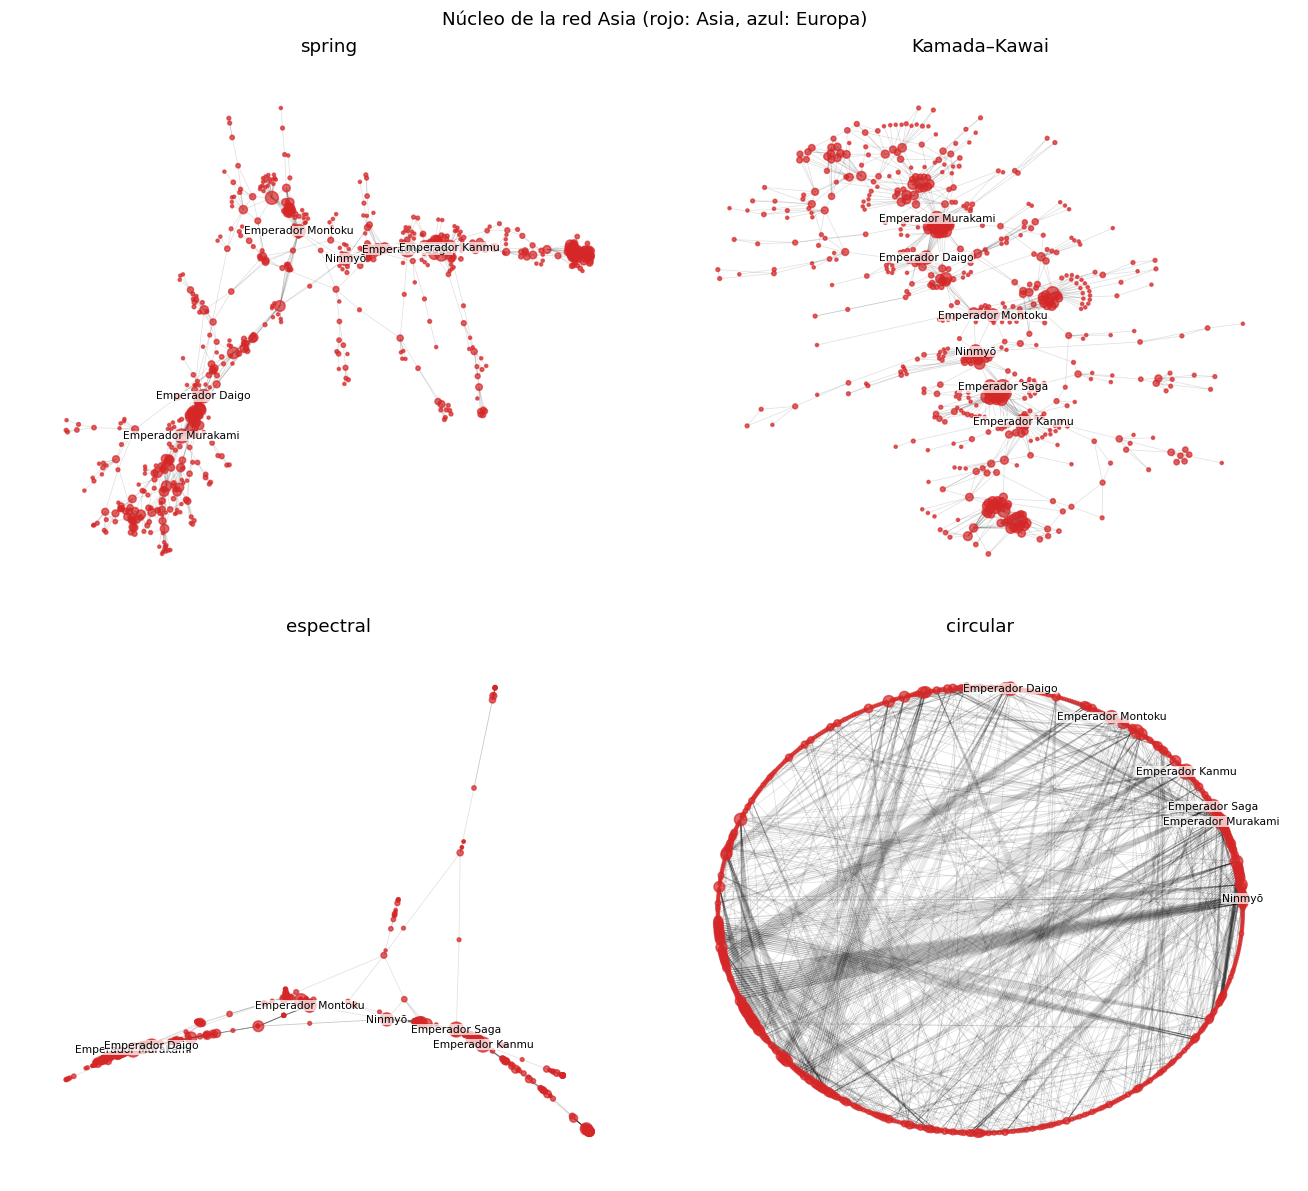

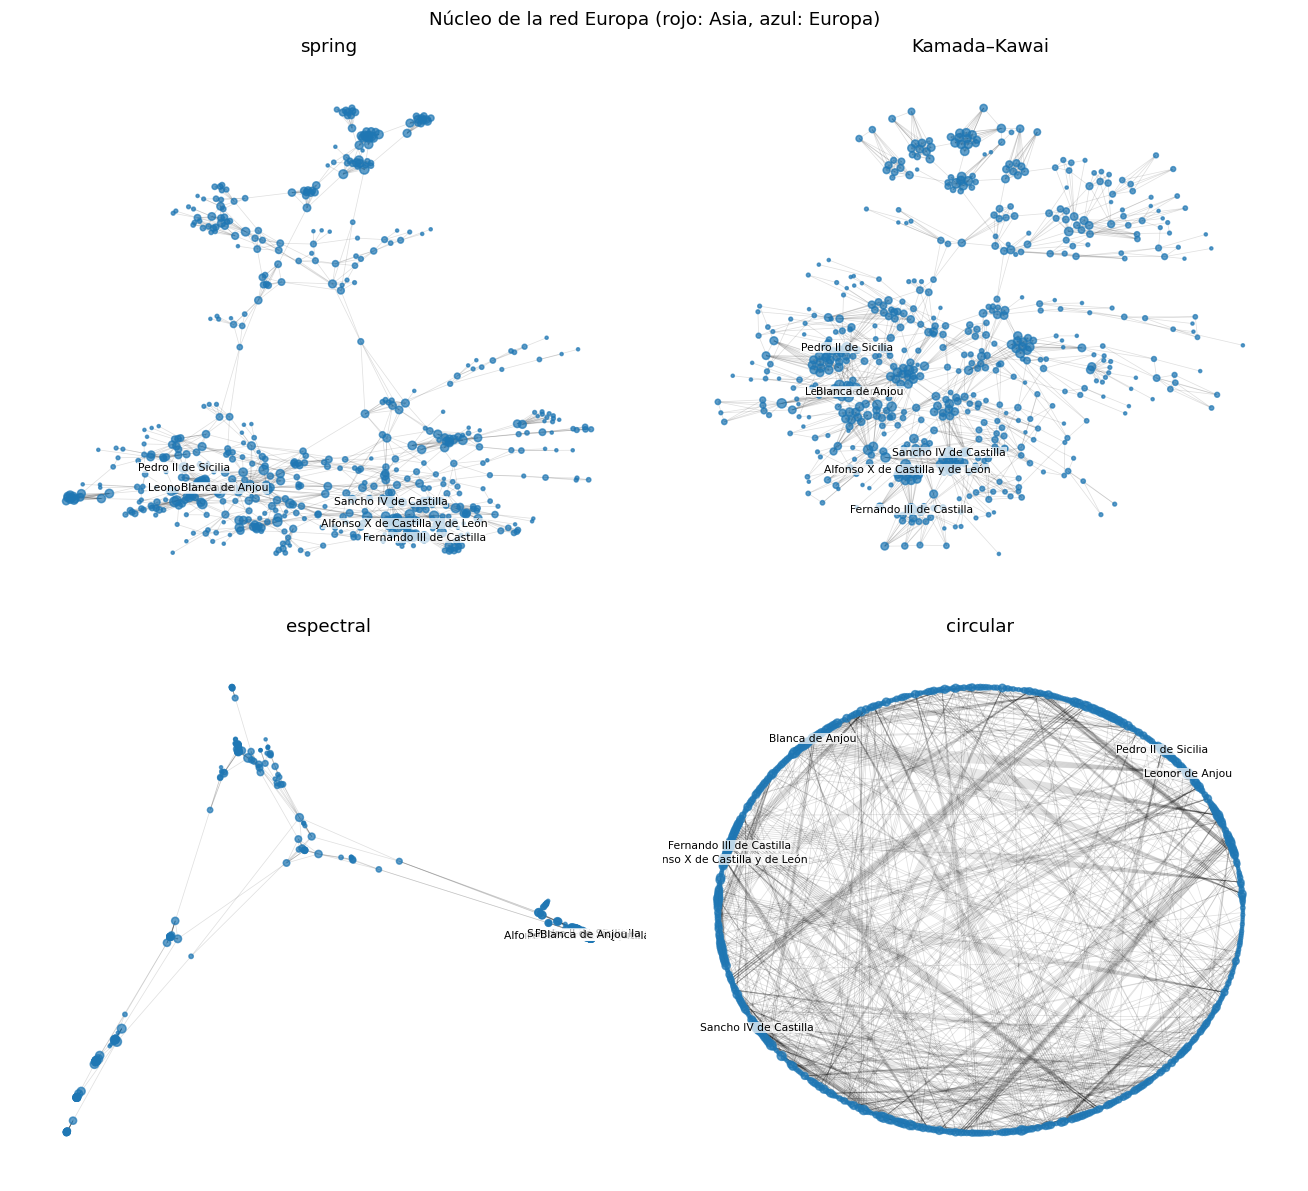

In [17]:
COLOR_CONTINENTE = {"Asia": "tab:red", "Europa": "tab:blue"}

def dibujar_layouts(G, layouts, titulo, camino=None, n_etiquetas=6):
    grados = dict(G.degree())
    top = sorted(grados, key=grados.get, reverse=True)[:n_etiquetas]
    colores = [COLOR_CONTINENTE[G.nodes[v]["continente"]] for v in G]
    fig, axs = plt.subplots(2, 2, figsize=(12, 11))
    for ax, (nombre_layout, pos) in zip(axs.flat, layouts.items()):
        nx.draw_networkx_edges(G, pos, alpha=0.12, width=0.5, ax=ax)
        nx.draw_networkx_nodes(G, pos, node_size=[2 + 2 * grados[v] for v in G], node_color=colores, alpha=0.7, ax=ax)
        etiquetas = {v: nombre(G, v) for v in (camino if camino else top)}
        if camino:
            aristas_camino = list(zip(camino[:-1], camino[1:]))
            nx.draw_networkx_edges(G, pos, edgelist=aristas_camino, width=2.5, edge_color="black", ax=ax)
            nx.draw_networkx_nodes(G, pos, nodelist=camino, node_size=40, node_color="black", ax=ax)
        nx.draw_networkx_labels(G, pos, labels=etiquetas, font_size=7, ax=ax,
                                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=0.3))
        ax.set_title(nombre_layout)
        ax.set_axis_off()
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()

for region in REGIONES:
    dibujar_layouts(nucleos[region], layouts[region], f"Núcleo de la red {region} (rojo: Asia, azul: Europa)")

En cada figura es la misma red en los cuatro dibujos. Lo único que cambia es dónde se ubican los nodos.

### Una visualización interactiva

Con cientos de nodos no se pueden poner todos los nombres. En el gráfico interactivo, al pasar el mouse sobre un nodo aparece la persona, su casa, su año y su grado; se puede hacer zoom con el mouse.

In [18]:
def red_interactiva(G, pos, titulo, camino=None):
    grados = dict(G.degree())
    ex, ey = [], []
    for u, v in G.edges():
        ex += [pos[u][0], pos[v][0], None]
        ey += [pos[u][1], pos[v][1], None]
    trazas = [go.Scatter(x=ex, y=ey, mode="lines", line=dict(width=0.4, color="#c8c8c8"), hoverinfo="none")]
    if camino:
        cx, cy = [], []
        for u, v in zip(camino[:-1], camino[1:]):
            cx += [pos[u][0], pos[v][0], None]
            cy += [pos[u][1], pos[v][1], None]
        trazas.append(go.Scatter(x=cx, y=cy, mode="lines", line=dict(width=3, color="black"), hoverinfo="none"))
    lista = list(G.nodes())
    en_camino = set(camino) if camino else set()
    trazas.append(go.Scatter(
        x=[pos[v][0] for v in lista], y=[pos[v][1] for v in lista], mode="markers",
        marker=dict(size=[5 + 0.4 * grados[v] for v in lista],
                    color=["black" if v in en_camino else
                           ("crimson" if G.nodes[v]["continente"] == "Asia" else "steelblue") for v in lista],
                    line=dict(width=0.5, color="white")),
        text=[f"{nombre(G, v)} ({v})<br>{G.nodes[v]['casa']}<br>año {G.nodes[v]['anio']}, grado {grados[v]}"
              for v in lista],
        hoverinfo="text"))
    fig = go.Figure(trazas)
    fig.update_layout(title=titulo, showlegend=False, width=850, height=700, plot_bgcolor="white",
                      xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
                      margin=dict(l=10, r=10, t=40, b=10))
    fig.show()

REGION_INTERACTIVA = "Mundo"   # ✏️ "Mundo", "Asia" o "Europa"
red_interactiva(nucleos[REGION_INTERACTIVA], layouts[REGION_INTERACTIVA]["spring"],
                f"Núcleo {REGION_INTERACTIVA} (layout spring): pasen el mouse sobre los nodos")

## 5. Caminos y distancias

La **distancia** $d_{ij}$ entre dos nodos es la cantidad mínima de aristas que hay que recorrer para ir de uno al otro (el camino más corto o **geodésico**). networkx la calcula con búsqueda en anchura (BFS). Puede haber varios caminos más cortos distintos entre el mismo par. Con `pesos=True` usamos la distancia $1/w$, que prefiere los vínculos padre/madre.

Como el camino casi nunca cae dentro del núcleo de la sección 4, lo dibujamos con un layout propio: el camino y los familiares directos de cada persona del camino.

In [19]:
def mostrar_camino(G, a, b, pesos=False):
    a, b = resolver(G, a), resolver(G, b)
    camino = nx.shortest_path(G, a, b, weight="distancia" if pesos else None)
    print(" → ".join(f"{nombre(G, v)}" for v in camino))
    print(f"Cantidad de pasos: {len(camino) - 1}")
    if not pesos:
        print(f"Caminos más cortos distintos: {sum(1 for _ in nx.all_shortest_paths(G, a, b))}")
    print("Vínculos del camino:", [G[u][v]["tipo"] for u, v in zip(camino[:-1], camino[1:])])
    return camino

print("Mundo, dentro de Europa:")
camino_europa = mostrar_camino(mundo, "Guillermo de Montreuil", "Vidkun de Bjarkøy")
print("\nMundo, de Europa a Asia:")
camino_mundo = mostrar_camino(mundo, "Carlomagno", "Gengis Kan")

Mundo, dentro de Europa:
Guillermo de Montreuil → Guillermo fitz Giroie → Giroie de Échauffour → Hadvise d'Echauffour → Judith de Évreux → Jordan of Hauteville → Felicia de Sicilia → Colomán de Hungría → Eufemia de Kiev → Mstislav I de Kiev → Malmfrid de Kiev → Cristina Sigurdsdatter → Erling Skakke → Krypinge-Orm Svensson → NN Sveinsdotter → Vidkun de Bjarkøy
Cantidad de pasos: 15
Caminos más cortos distintos: 2
Vínculos del camino: ['padre', 'padre', 'padre', 'madre', 'madre', 'hermano', 'conyuge', 'conyuge', 'hermano', 'padre', 'madre', 'conyuge', 'padre', 'hermano', 'conyuge']

Mundo, de Europa a Asia:
Carlomagno → Ludovico Pío → Gisela → Adelardo → Eberhard I, Count of Zürich → Judith von Friaul → Leopoldo I de Austria → Adalberto el Victorioso → Ernesto de Austria → Leopoldo II de Austria → Leopoldo III de Babenberg → Judit de Babenberg → Bonifacio de Montferrato → Guillermo VI de Montferrato → Bonifacio II de Montferrato → Guillermo VII de Montferrato → Irene de Montferrato → An

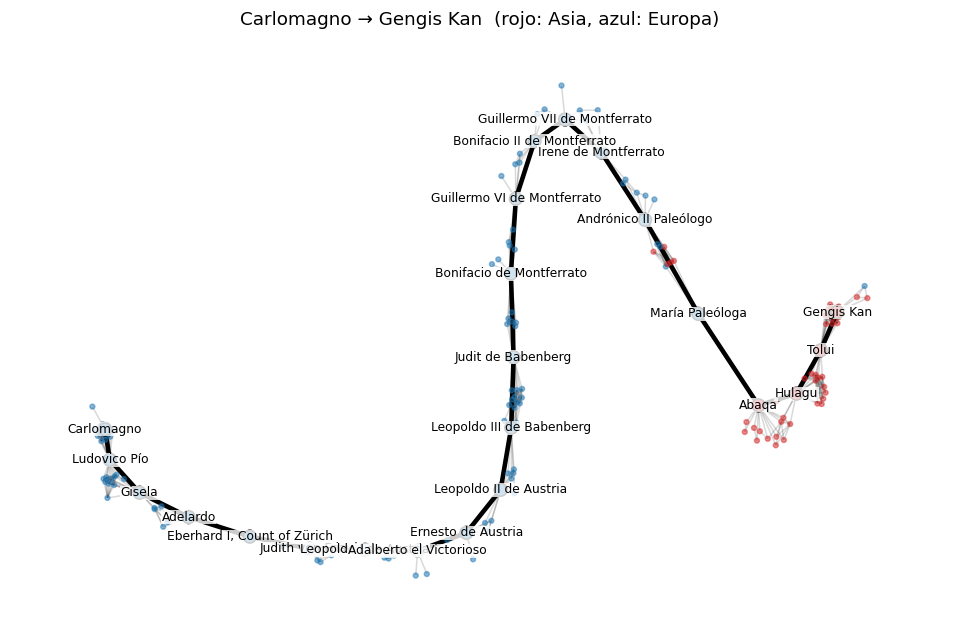

In [20]:
def dibujar_camino(G, camino, titulo, max_vecinos=15):
    entorno = set(camino)
    for v in camino:
        entorno.update(sorted(G.neighbors(v), key=G.degree, reverse=True)[:max_vecinos])
    H = inducido(G, entorno)
    pos = nx.spring_layout(H, seed=SEMILLA, iterations=200,
                           pos={v: (i, 0) for i, v in enumerate(camino)}, fixed=None)
    fig, ax = plt.subplots(figsize=(11, 7))
    nx.draw_networkx_edges(H, pos, alpha=0.15, ax=ax)
    nx.draw_networkx_nodes(H, pos, node_size=10, node_color=[COLOR_CONTINENTE[H.nodes[v]["continente"]] for v in H],
                           alpha=0.5, ax=ax)
    nx.draw_networkx_edges(H, pos, edgelist=list(zip(camino[:-1], camino[1:])), width=3, edge_color="black", ax=ax)
    nx.draw_networkx_nodes(H, pos, nodelist=camino, node_size=70,
                           node_color=[COLOR_CONTINENTE[H.nodes[v]["continente"]] for v in camino],
                           edgecolors="black", ax=ax)
    nx.draw_networkx_labels(H, pos, labels={v: nombre(H, v) for v in camino}, font_size=8, ax=ax,
                            bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=0.3))
    ax.set_title(titulo + "  (rojo: Asia, azul: Europa)")
    ax.set_axis_off()
    plt.show()

dibujar_camino(mundo, camino_mundo, "Carlomagno → Gengis Kan")

Exploren otros pares. Escriban un nombre exacto o un `Id` (los nombres repetidos piden el `Id`; para buscar usen `buscar(mundo, "texto")`).

In [21]:
def explorador():
    @widgets.interact_manual(region=widgets.Dropdown(options=REGIONES, value="Mundo", description="Red"),
                             persona_a=widgets.Text(value="Carlomagno", description="Persona A"),
                             persona_b=widgets.Text(value="Gengis Kan", description="Persona B"),
                             con_pesos=widgets.Checkbox(value=False, description="usar pesos"))
    def _(region, persona_a, persona_b, con_pesos):
        G = redes[region]
        try:
            a, b = resolver(G, persona_a), resolver(G, persona_b)
            if a == b:
                print("Elijan dos personas distintas.")
                return
            camino = mostrar_camino(G, a, b, pesos=con_pesos)
        except (ValueError, nx.NetworkXNoPath, nx.NodeNotFound) as e:
            print(e)
            return
        dibujar_camino(G, camino, f"{nombre(G, a)} → {nombre(G, b)} ({region})")

explorador()

interactive(children=(Dropdown(description='Red', options=('Mundo', 'Asia', 'Europa'), value='Mundo'), Text(va…

## 6. Desafío: ¿quiénes son las dos personas más lejanas?

**Paso 1, a ojo.** Elijan dos personas que les parezca que están **muy lejos** en la red (lejos en el tiempo, en el espacio, de dinastías distintas...). Escríbanlas abajo y calculen su distancia. Anoten el resultado antes de seguir.

In [22]:
# ✏️ Escriban acá su apuesta
mi_a = "Carlomagno"
mi_b = "Gengis Kan"

mi_distancia = nx.shortest_path_length(mundo, resolver(mundo, mi_a), resolver(mundo, mi_b))
print(f"Distancia entre {mi_a} y {mi_b}: {mi_distancia}")

Distancia entre Carlomagno y Gengis Kan: 22


**Paso 2, la respuesta.** La **excentricidad** de un nodo es su distancia al nodo más lejano. El **diámetro** es la excentricidad máxima: la distancia más grande entre todos los pares. Los nodos con excentricidad igual al diámetro forman la **periferia**, y los de excentricidad mínima, el **centro**.

Estas medidas sólo tienen sentido si la red es **conexa**; si no, hay pares a distancia infinita. Nuestras redes no lo son, así que las calculamos sobre la **componente gigante** de cada una.

Para 15.000 nodos hay más de 100 millones de pares. `nx.eccentricity` tardaría demasiado, así que hacemos los BFS con `scipy.sparse.csgraph.shortest_path` (escrito en C), por bloques de filas para no llenar la memoria. Con eso obtenemos en una sola pasada la excentricidad, la distribución de distancias y la closeness de cada nodo.

In [23]:
def analizar_distancias(G, bloque=500):
    # G debe ser conexo. Devuelve excentricidad, closeness y distribución de distancias (exactas)
    lista = list(G)
    A = nx.to_scipy_sparse_array(G, nodelist=lista, weight=None, format="csr")
    N = len(lista)
    exc, suma, cuentas = np.zeros(N, dtype=int), np.zeros(N), np.zeros(1, dtype=np.int64)
    for inicio in range(0, N, bloque):
        filas = np.arange(inicio, min(N, inicio + bloque))
        D = shortest_path(A, directed=False, unweighted=True, indices=filas).astype(np.int32)
        exc[filas] = D.max(axis=1)
        suma[filas] = D.sum(axis=1)
        c = np.bincount(D.ravel())
        cuentas = np.pad(cuentas, (0, max(0, len(c) - len(cuentas)))); cuentas[:len(c)] += c
    cuentas[0] -= N                 # sacamos la diagonal (d = 0)
    cuentas //= 2                   # cada par se contó dos veces
    return {"excentricidad": pd.Series(exc, index=lista),
            "closeness": pd.Series((N - 1) / suma, index=lista),
            "distribucion": pd.Series(cuentas[1:], index=range(1, len(cuentas))),
            "diametro": int(exc.max()), "radio": int(exc.min()),
            "distancia media": float((np.arange(len(cuentas)) * cuentas).sum() / cuentas.sum())}

gigantes = {region: gigante(G) for region, G in redes.items()}
distancias = {}
for region, Gg in gigantes.items():
    distancias[region] = analizar_distancias(Gg)
    print(f"{region:7s} gigante de {Gg.number_of_nodes():5d} nodos: diámetro = {distancias[region]['diametro']}, "
          f"radio = {distancias[region]['radio']}, distancia media = {distancias[region]['distancia media']:.2f}")
print("\nSu apuesta llegó a:", mi_distancia)

Mundo   gigante de 15242 nodos: diámetro = 62, radio = 31, distancia media = 14.23
Asia    gigante de  1362 nodos: diámetro = 41, radio = 21, distancia media = 12.61


Europa  gigante de 13578 nodos: diámetro = 57, radio = 29, distancia media = 13.54

Su apuesta llegó a: 22


In [24]:
for region, Gg in gigantes.items():
    exc = distancias[region]["excentricidad"]
    centro, periferia = exc[exc == exc.min()].index, exc[exc == exc.max()].index
    print(f"--- {region}")
    print(f"  Centro ({len(centro)}):", [nombre(Gg, v) for v in centro[:10]])
    print(f"  Periferia ({len(periferia)}):", [nombre(Gg, v) for v in periferia[:10]])

--- Mundo
  Centro (1): ['Galindo I Aznárez de Aragón']
  Periferia (4): ['Khadija Arslan Khatun', 'Æthelburh of Wilton', 'unnamed wife of King Egbert of Wessex', 'Cynethryth']
--- Asia
  Centro (15): ['Emperador Murakami', 'Emperador Daigo', 'Senshi-naishinnō', 'Kinshi-naishinnō', 'Gashi-naishinnō', 'Eishi-naishinnō', 'Emperador Suzaku', 'Enshi-naishinnō', 'Kyōshi-naishinnō', 'Shōshi-naishinnō']
  Periferia (3): ['Hōjō Tokiyuki', 'Adachi Munekage', 'Yamashiro']
--- Europa
  Centro (10): ['Eberhard I, Count of Zürich', 'Roberto el Fuerte', 'Conrado II de Borgoña', 'Heriberto I de Vermandois', 'Raoul of Flanders', 'Adelaida deTours', 'Balduino II de Flandes', 'Judith de Francia', 'Carlos III de Francia', 'Balduino I de Flandes']
  Periferia (9): ['Mechtild of Schwarzburg-Wachsenburg', 'Pedro de Bobadilla', 'Jelisaveta Crnojević', 'Skenderbeg Crnojević', 'Æthelburh of Wilton', 'unnamed wife of King Egbert of Wessex', 'Francisco de Bobadilla (obispo)', 'Cynethryth', 'Pedro de Cabrera y Ca

In [25]:
def pares_lejanos(Gg, dist, max_pares=10):
    # Pares a distancia igual al diámetro: basta con BFS desde los nodos de la periferia
    exc, diam = dist["excentricidad"], dist["diametro"]
    pares = set()
    for u in exc[exc == diam].index:
        for v, d in nx.single_source_shortest_path_length(Gg, u).items():
            if d == diam:
                pares.add(tuple(sorted((u, v))))
    return sorted(pares)[:max_pares], len(pares)

lejanos = {}
for region, Gg in gigantes.items():
    lejanos[region], total = pares_lejanos(Gg, distancias[region])
    print(f"{region}: hay {total} pares a distancia {distancias[region]['diametro']}. Algunos:")
    for u, v in lejanos[region][:5]:
        print(f"   {nombre(Gg, u)} ({Gg.nodes[u]['anio']})  —  {nombre(Gg, v)} ({Gg.nodes[v]['anio']})")

camino_diametro = nx.shortest_path(gigantes["Mundo"], *lejanos["Mundo"][0])
print("\nUno de los caminos más largos del Mundo:")
print(" → ".join(nombre(mundo, v) for v in camino_diametro))

Mundo: hay 3 pares a distancia 62. Algunos:
   Khadija Arslan Khatun (1001)  —  Æthelburh of Wilton (771)
   Khadija Arslan Khatun (1001)  —  Cynethryth (659)
   Khadija Arslan Khatun (1001)  —  unnamed wife of King Egbert of Wessex (771)
Asia: hay 2 pares a distancia 41. Algunos:
   Adachi Munekage (1250)  —  Yamashiro (650)
   Yamashiro (650)  —  Hōjō Tokiyuki (1326)
Europa: hay 18 pares a distancia 57. Algunos:
   Mechtild of Schwarzburg-Wachsenburg (1406)  —  Æthelburh of Wilton (771)
   Mechtild of Schwarzburg-Wachsenburg (1406)  —  Cynethryth (659)
   Mechtild of Schwarzburg-Wachsenburg (1406)  —  unnamed wife of King Egbert of Wessex (771)
   Pedro de Bobadilla (1401)  —  Æthelburh of Wilton (771)
   Pedro de Bobadilla (1401)  —  Cynethryth (659)

Uno de los caminos más largos del Mundo:
Khadija Arslan Khatun → Al-Qa'im → Al-Qadir → Ishaq ibn al-Muqtadir → Al-Muti → Al-Muqtadir → Al-Mutadid → Al-Muwaffaq → Al-Mu'tazz → Al-Mutawakkil → Al-Mutásim → Harún al-Rashid → Al-Mahdi → Al

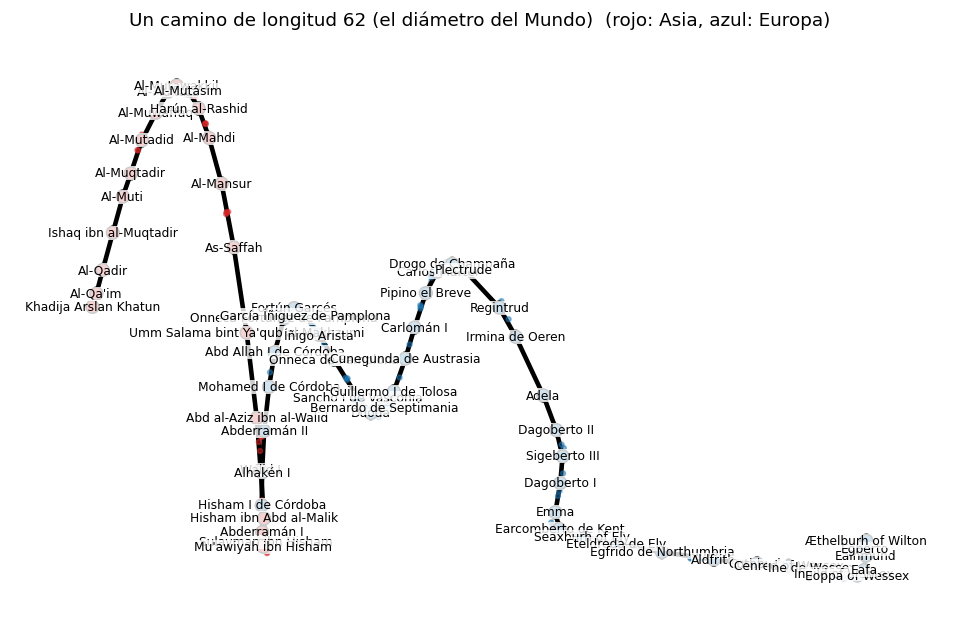

In [26]:
dibujar_camino(mundo, camino_diametro, f"Un camino de longitud {distancias['Mundo']['diametro']} (el diámetro del Mundo)", max_vecinos=5)

**Paso 3, ¿qué visualización ayudaba más?** El camino del diámetro de la red completa no entra en el núcleo, así que repetimos el desafío *dentro* del núcleo de cada región: buscamos su diámetro y lo marcamos en los cuatro layouts.

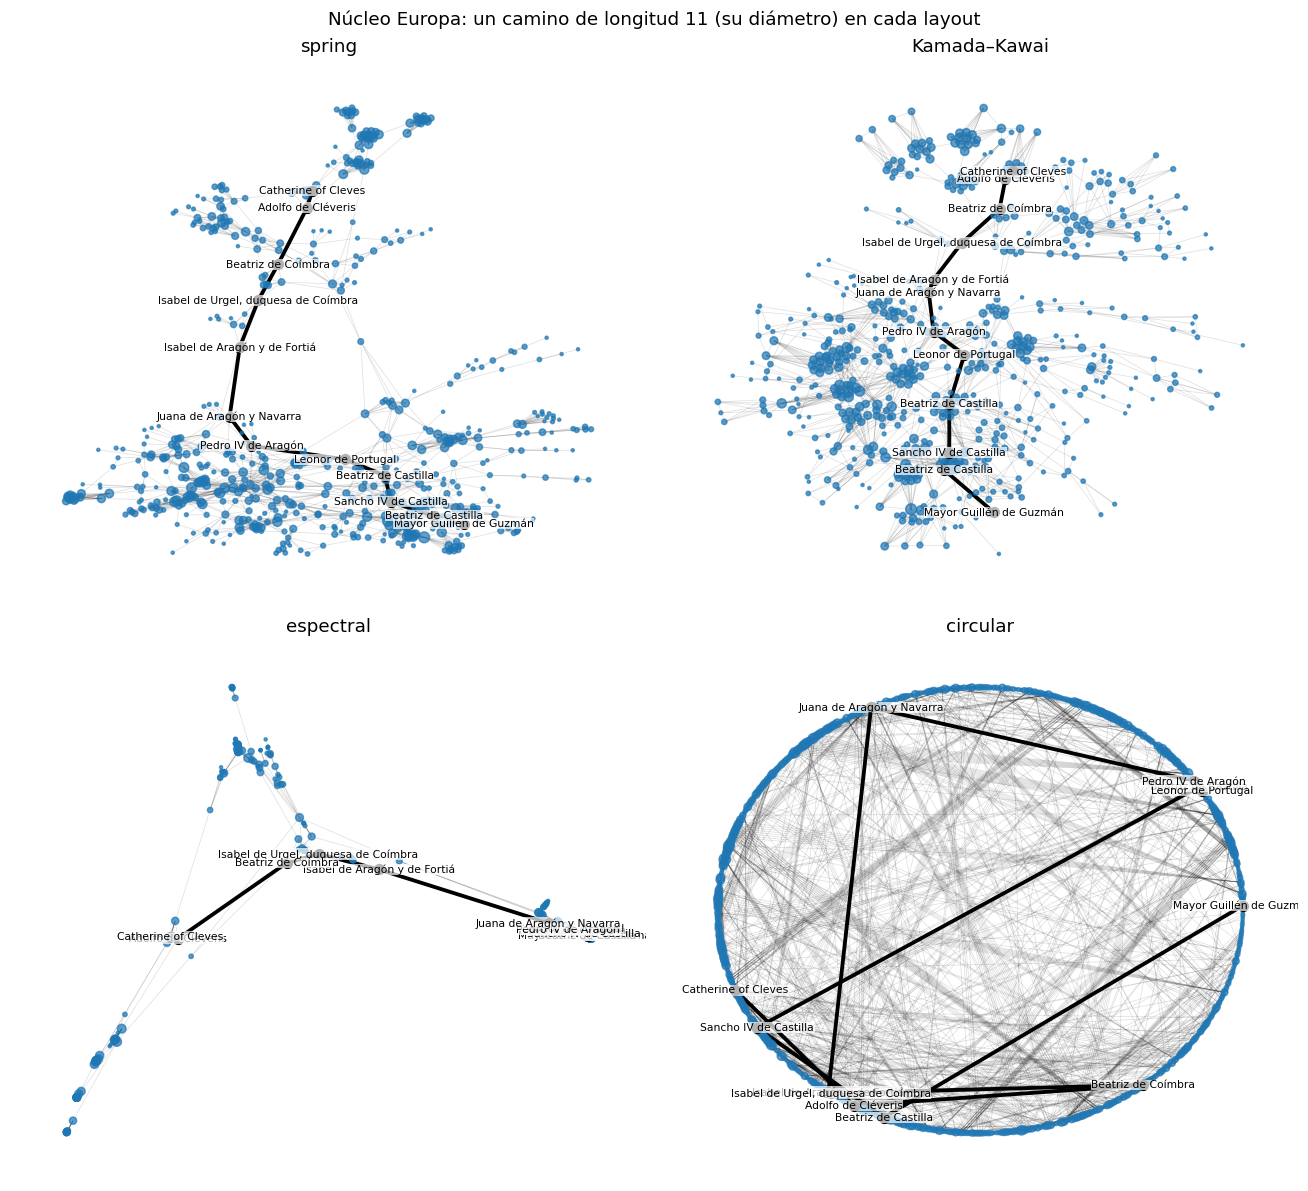

In [27]:
REGION_DESAFIO = "Europa"    # ✏️ "Mundo", "Asia" o "Europa"

H = nucleos[REGION_DESAFIO]
dist_nucleo = dict(nx.all_pairs_shortest_path_length(H))
diam_nucleo = max(max(d.values()) for d in dist_nucleo.values())
u_lejos = next(u for u in H if max(dist_nucleo[u].values()) == diam_nucleo)
v_lejos = max(dist_nucleo[u_lejos], key=dist_nucleo[u_lejos].get)
camino_nucleo = nx.shortest_path(H, u_lejos, v_lejos)
dibujar_layouts(H, layouts[REGION_DESAFIO],
                f"Núcleo {REGION_DESAFIO}: un camino de longitud {diam_nucleo} (su diámetro) en cada layout",
                camino=camino_nucleo)

En un dibujo, dos nodos que se ven lejos no necesariamente están lejos en la red, y viceversa. Podemos medir qué tan fiel es cada layout comparando, para todos los pares, la distancia en el dibujo (euclídea) con la distancia en la red. Si el layout fuera perfecto, una crecería con la otra; la **correlación de Spearman** mide qué tan bien se ordenan juntas (1 = mismo orden).

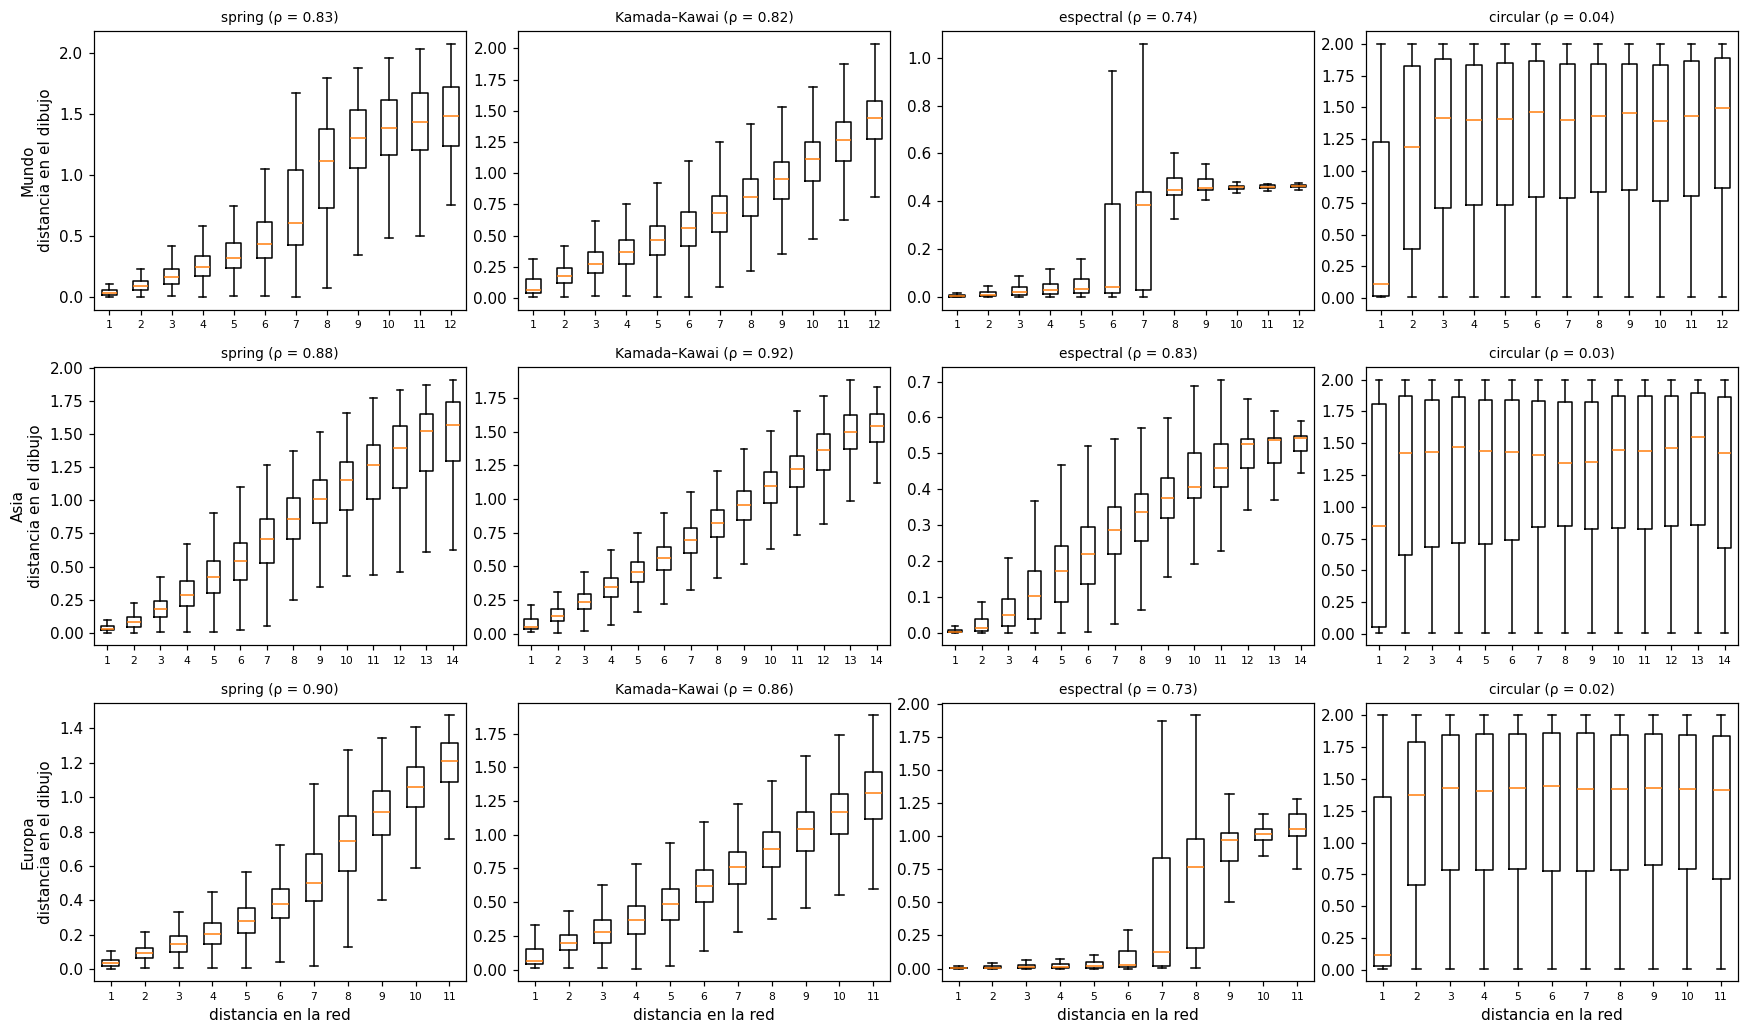

,spring,Kamada–Kawai,espectral,circular
Spearman,,,,
Mundo,0.83,0.82,0.74,0.04
Asia,0.88,0.92,0.83,0.03
Europa,0.90,0.86,0.73,0.02


In [28]:
def fidelidad_layouts(H, layouts_H, ax_fila=None):
    lista = list(H)
    dist = dict(nx.all_pairs_shortest_path_length(H))
    d_red = np.array([dist[u][v] for i, u in enumerate(lista) for v in lista[i + 1:]])
    rhos = {}
    for j, (nombre_layout, pos) in enumerate(layouts_H.items()):
        d_dibujo = pdist(np.array([pos[v] for v in lista]))   # mismas parejas y mismo orden que d_red
        rhos[nombre_layout] = spearmanr(d_red, d_dibujo)[0]
        if ax_fila is not None:
            ax = ax_fila[j]
            diam = d_red.max()
            ax.boxplot([d_dibujo[d_red == d] for d in range(1, diam + 1)], showfliers=False)
            ax.set_xticks(range(1, diam + 1), range(1, diam + 1), fontsize=7)
            ax.set_title(f"{nombre_layout} (ρ = {rhos[nombre_layout]:.2f})", fontsize=9)
    return rhos

fig, axs = plt.subplots(3, 4, figsize=(16, 9.5))
tabla_rho = {}
for fila, region in zip(axs, REGIONES):
    tabla_rho[region] = fidelidad_layouts(nucleos[region], layouts[region], fila)
    fila[0].set_ylabel(f"{region}\ndistancia en el dibujo")
for ax in axs[-1]:
    ax.set_xlabel("distancia en la red")
plt.tight_layout(); plt.show()

pd.DataFrame(tabla_rho).T.round(2).rename_axis("Spearman")

Kamada–Kawai es el layout que intenta respetar las distancias; en estas redes spring le anda muy cerca, porque la red es casi un "árbol" de generaciones que el resorte estira bien. El espectral concentra a la mayoría de los nodos en pocos puntos y sólo separa los grupos más alejados. El circular no usa la estructura de la red para ubicar los nodos, así que su dibujo no dice nada de las distancias (ρ ≈ 0).

### Distancia media y distribución de distancias

La **distancia media** $\langle d \rangle$ es el promedio de $d_{ij}$ sobre todos los pares de la componente gigante. Conviene mirar además la distribución completa.

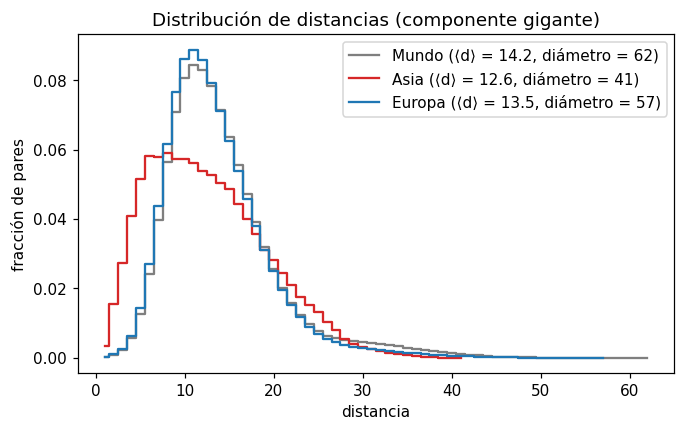

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
for region in REGIONES:
    dist = distancias[region]["distribucion"]
    ax.step(dist.index, dist.values / dist.sum(), where="mid", lw=1.5, color=COLORES[region],
            label=f"{region} (⟨d⟩ = {distancias[region]['distancia media']:.1f}, diámetro = {distancias[region]['diametro']})")
ax.set(xlabel="distancia", ylabel="fracción de pares", title="Distribución de distancias (componente gigante)")
ax.legend(); plt.show()

Una red genealógica no es un "mundo pequeño" en el mismo sentido que una red social: los vínculos sólo unen a personas de generaciones cercanas, así que para ir de un extremo al otro hay que recorrer muchas generaciones. ¿Eso es mucho o poco? Para responderlo hace falta compararla con un modelo de referencia (por ejemplo una red aleatoria con el mismo grado medio), que es el tema de la próxima clase.

## 7. Conectividad

Una red no dirigida es **conexa** si hay un camino entre cualquier par de nodos. Si no, se parte en **componentes conexas**, y la más grande es la **componente gigante**.

In [30]:
def mostrar_componentes(G, tamano_min=10, n_max=8):
    comps = sorted(nx.connected_components(G), key=len, reverse=True)
    print(f"{len(comps)} componentes ({sum(1 for c in comps if len(c) == 1)} personas aisladas)")
    for c in comps[:n_max]:
        if len(c) >= tamano_min:
            casas = pd.Series([G.nodes[v]["casa"] for v in c if G.nodes[v]["casa"]]).value_counts()
            muestra = sorted(c, key=G.degree, reverse=True)[:4]
            print(f"  {len(c):5d} personas. Casas más comunes: {', '.join(casas.index[:3])}. "
                  f"Hubs: {', '.join(nombre(G, v) for v in muestra)}")

for region, G in redes.items():
    print(f"--- {region}: ", end="")
    mostrar_componentes(G)

--- Mundo: 74 componentes (52 personas aisladas)
  15242 personas. Casas más comunes: Casa de Borgoña, Casa de Wessex, Hårfagreætta. Hubs: Erico I de Noruega, Ludovico Pío, Gengis Kan, Haroldo I de Noruega
   1362 personas. Casas más comunes: Familia imperial japonesa, Hokke, Clan Hōjō. Hubs: Emperador Saga, Emperador Kanmu, Emperador Murakami, Emperador Daigo
    747 personas. Casas más comunes: House of Li, Clan Xiao of Lanling, House of Yang. Hubs: Li Shimin, Su Zong, Li Mao, Princess Xianyi
    397 personas. Casas más comunes: House of Zhao, dinastía Jin, Knight Escort Lieutenant. Hubs: Song Huizong, Song Gaozong, Qinzong, Ande Diji
    116 personas. Casas más comunes: Dinastía Liao. Hubs: Emperador Xingzong, Yelü Zongyuan, Yelü Zhongyuan, Liao Shengzong
     34 personas. Casas más comunes: Dinastía frigia, Familia Mamiconio, César. Hubs: Miguel III, Teodora, Bardas, Hamazasp IV Mamikonian
     12 personas. Casas más comunes: Piasts of Mazovia, Casa de Olelkovich, gedimínidas. Hubs

### 7.1 Quedarse sólo con los vínculos fuertes

¿Qué pasa si sólo consideramos los vínculos de peso al menos $w_{\min}$? Con $w_{\min} = 2$ descartamos a los hermanos y con $w_{\min} = 3$ nos quedamos sólo con el árbol genealógico (padre/madre).

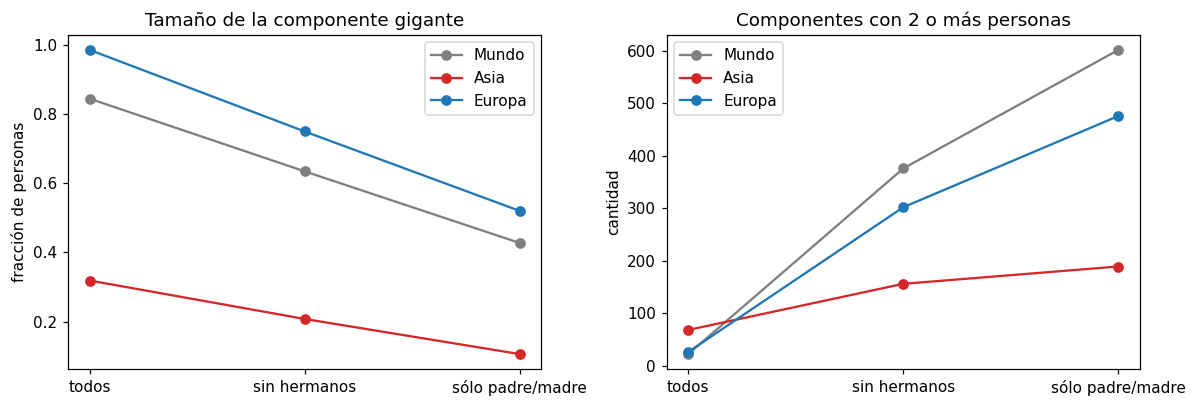

,red,vínculos,fracción gigante,componentes con 2+ personas,aislados
0,Mundo,todos,0.844,22,52
1,Mundo,sin hermanos,0.634,376,2677
2,Mundo,sólo padre/madre,0.427,602,5420
3,Asia,todos,0.319,68,42
4,Asia,sin hermanos,0.207,156,996
5,Asia,sólo padre/madre,0.106,189,1889
6,Europa,todos,0.985,26,54
7,Europa,sin hermanos,0.749,302,1773
8,Europa,sólo padre/madre,0.520,476,3657


In [31]:
def filtrar_por_peso(G, w_min):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= w_min)
    return H

UMBRALES = {1: "todos", 2: "sin hermanos", 3: "sólo padre/madre"}
filas = []
for region, G in redes.items():
    for w, descripcion in UMBRALES.items():
        comps = list(nx.connected_components(filtrar_por_peso(G, w)))
        filas.append({"red": region, "vínculos": descripcion,
                      "fracción gigante": max(len(c) for c in comps) / G.number_of_nodes(),
                      "componentes con 2+ personas": sum(1 for c in comps if len(c) >= 2),
                      "aislados": sum(1 for c in comps if len(c) == 1)})
tabla_umbral = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for region in REGIONES:
    t = tabla_umbral[tabla_umbral["red"] == region]
    ax[0].plot(t["vínculos"], t["fracción gigante"], "o-", label=region, color=COLORES[region])
    ax[1].plot(t["vínculos"], t["componentes con 2+ personas"], "o-", label=region, color=COLORES[region])
ax[0].set(ylabel="fracción de personas", title="Tamaño de la componente gigante")
ax[1].set(ylabel="cantidad", title="Componentes con 2 o más personas")
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.show()
tabla_umbral.round(3)

In [32]:
# ✏️ Prueben otras redes y umbrales
print("Mundo, sólo padre/madre: ", end="")
mostrar_componentes(filtrar_por_peso(mundo, 3), tamano_min=50)

Mundo, sólo padre/madre: 6022 componentes (5420 personas aisladas)
   7711 personas. Casas más comunes: Casa de Borgoña, Hårfagreætta, Casa de Estridsson. Hubs: Haroldo I de Noruega, Alfonso IX de León, Carlomagno, Carlos de Valois
    453 personas. Casas más comunes: Familia imperial japonesa, Hokke, clan Fujiwara. Hubs: Emperador Kanmu, Emperador Daigo, Emperador Montoku, Emperador Tenji
    315 personas. Casas más comunes: House of Li, Dou Clan of Henan, Yang clan of Hongnong. Hubs: Xuanzong de Tang, Li Shimin, Gaozu de Tang, Xian Zong
    264 personas. Casas más comunes: Familia Gonzaga, House of Nassau-Siegen (1303-1607), Casa de Este. Hubs: Nicolás III de Este, Inés de Borgoña, Carlos I de Borbón, Isabel de Baviera, electora de Brandenburgo
    242 personas. Casas más comunes: House of Zhao. Hubs: Song Huizong, Song Shenzong, Song Renzong, Song Taizong
    118 personas. Casas más comunes: gengiskánidas, Borjigin, Ilkhanids. Hubs: Gengis Kan, Borte, Kublai Kan, Tolui
    101 perso

Sin los vínculos de hermano y cónyuge, la red se parte en **linajes**: los matrimonios son los que unen a las dinastías entre sí.

### 7.2 Personas y vínculos que mantienen conectada la red

- Un **punto de articulación** es un nodo cuya remoción desconecta la red.
- Un **puente** es una arista cuya remoción desconecta la red.

Sacar cada punto de articulación y recalcular componentes sería muy lento con miles de ellos. En cambio, usamos el **árbol de bloques** (las componentes biconexas unidas por los puntos de articulación): con un único recorrido sabemos cuántas personas quedan de cada lado al sacar cada punto.

In [33]:
def impacto_articulaciones(G):
    # Para G conexo: cuántas personas quedan separadas de la parte más grande al sacar cada punto de articulación
    arts = set(nx.articulation_points(G))
    if not arts:
        return pd.Series(dtype=int)
    T, peso = nx.Graph(), {a: 1 for a in arts}
    for i, bloque in enumerate(nx.biconnected_components(G)):
        b = ("bloque", i)
        peso[b] = sum(1 for v in bloque if v not in arts)
        T.add_edges_from((b, a) for a in bloque & arts)
    raiz = next(iter(arts))
    padre = dict(nx.bfs_predecessors(T, raiz))
    debajo = dict(peso)                                   # personas en el subárbol de cada nodo de T
    for x in reversed(list(nx.bfs_tree(T, raiz))):
        if x != raiz:
            debajo[padre[x]] += debajo[x]
    total = G.number_of_nodes()
    impacto = {}
    for a in arts:
        partes = [debajo[h] for h in T[a] if padre.get(h) == a]
        if a != raiz:
            partes.append(total - debajo[a])
        impacto[a] = total - 1 - max(partes)
    return pd.Series(impacto).sort_values(ascending=False)

impactos = {}
for region, Gg in gigantes.items():
    impactos[region] = impacto_articulaciones(Gg)
    puentes = list(nx.bridges(Gg))
    hojas = sum(1 for u, v in puentes if Gg.degree(u) == 1 or Gg.degree(v) == 1)
    print(f"--- {region} (componente gigante): {len(impactos[region])} puntos de articulación, "
          f"{len(puentes)} puentes ({hojas} van a una persona de grado 1)")
    for v, n_sep in impactos[region].head(5).items():
        print(f"   {nombre(Gg, v):40s} al sacarlo quedan {n_sep} personas separadas")

--- Mundo (componente gigante): 3411 puntos de articulación, 3822 puentes (3061 van a una persona de grado 1)
   Hulagu                                   al sacarlo quedan 288 personas separadas
   Onneca Fortúnez de Pamplona              al sacarlo quedan 226 personas separadas
   Abd Allah I de Córdoba                   al sacarlo quedan 225 personas separadas
   Mohamed I de Córdoba                     al sacarlo quedan 223 personas separadas
   Abderramán II                            al sacarlo quedan 222 personas separadas
--- Asia (componente gigante): 273 puntos de articulación, 533 puentes (470 van a una persona de grado 1)
   Emperador Takakura                       al sacarlo quedan 181 personas separadas
   Emperador Go-Toba                        al sacarlo quedan 158 personas separadas
   Emperador Tsuchimikado                   al sacarlo quedan 128 personas separadas
   Taira no Kiyomori                        al sacarlo quedan 128 personas separadas
   Tokiwa Gozen    

--- Europa (componente gigante): 3061 puntos de articulación, 3283 puentes (2608 van a una persona de grado 1)
   Peter I of Rosenberg                     al sacarlo quedan 47 personas separadas
   Tora Magnusdatter                        al sacarlo quedan 47 personas separadas
   Jón Loftsson                             al sacarlo quedan 44 personas separadas
   Clemente VII                             al sacarlo quedan 42 personas separadas
   Enrique de Trastámara de Aragón          al sacarlo quedan 40 personas separadas


In [34]:
# Verificación: para los primeros puntos, sacamos el nodo y contamos a mano
Gg = gigantes["Asia"]
for v in impactos["Asia"].index[:3]:
    H = Gg.copy(); H.remove_node(v)
    tamanos = sorted((len(c) for c in nx.connected_components(H)), reverse=True)
    print(f"{nombre(Gg, v)}: árbol de bloques = {impactos['Asia'][v]}, a mano = {sum(tamanos[1:])}")

Emperador Takakura: árbol de bloques = 181, a mano = 181
Emperador Go-Toba: árbol de bloques = 158, a mano = 158
Emperador Tsuchimikado: árbol de bloques = 128, a mano = 128


### 7.3 Robustez: ¿cuántas personas hay que sacar para romper la red?

Sacamos personas de a poco, en orden de grado (primero los hubs) o al azar, y miramos el tamaño de la componente gigante que queda.

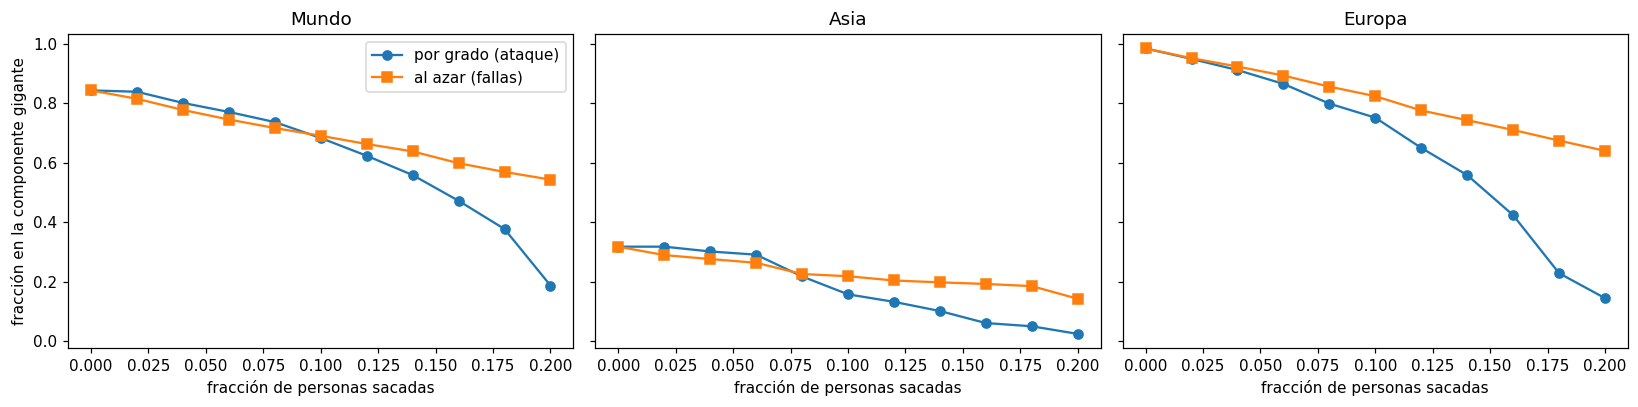

In [35]:
def curva_robustez(G, orden, fracciones):
    N = G.number_of_nodes()
    resultado = []
    for f in fracciones:
        H = G.copy()
        H.remove_nodes_from(orden[:int(f * N)])
        resultado.append(max((len(c) for c in nx.connected_components(H)), default=0) / N)
    return resultado

fracciones = np.linspace(0, 0.2, 11)
rng = np.random.default_rng(SEMILLA)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (region, G) in zip(axs, redes.items()):
    por_grado = sorted(G, key=G.degree, reverse=True)
    al_azar = list(rng.permutation(list(G)))
    ax.plot(fracciones, curva_robustez(G, por_grado, fracciones), "o-", label="por grado (ataque)")
    ax.plot(fracciones, curva_robustez(G, al_azar, fracciones), "s-", label="al azar (fallas)")
    ax.set(xlabel="fracción de personas sacadas", title=region)
axs[0].set_ylabel("fracción en la componente gigante")
axs[0].legend()
plt.tight_layout(); plt.show()

In [36]:
# ✏️ ¿Qué pasa si sacamos a una persona o a varias? Prueben con otras.
def sacar(G, personas):
    H = G.copy()
    H.remove_nodes_from([resolver(G, p) for p in personas])
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    print(f"Sin {', '.join(personas)}: {len(comps)} componentes; la gigante tiene {len(comps[0])} personas "
          f"(antes {len(max(nx.connected_components(G), key=len))})")

sacar(mundo, ["Gengis Kan"])
sacar(mundo, ["Carlomagno", "Hugo Capeto", "Guillermo I de Inglaterra"])

Sin Gengis Kan: 80 componentes; la gigante tiene 15233 personas (antes 15242)
Sin Carlomagno, Hugo Capeto, Guillermo I de Inglaterra: 75 componentes; la gigante tiene 15238 personas (antes 15242)


## 8. Coeficiente de clustering

El **coeficiente de clustering local** de un nodo responde: ¿qué fracción de los pares de vecinos están conectados entre sí?

$$C_i = \frac{2\, e_i}{k_i (k_i - 1)}$$

donde $e_i$ es la cantidad de aristas entre los $k_i$ vecinos de $i$. Calculémoslo a mano para Carlomagno y comparémoslo con networkx.

In [37]:
v = resolver(mundo, "Carlomagno")
vecinos = list(mundo.neighbors(v))
k_i = len(vecinos)
e_i = mundo.subgraph(vecinos).number_of_edges()
print(f"{nombre(mundo, v)}: k = {k_i} vecinos, e = {e_i} aristas entre ellos")
print(f"C a mano:      {2 * e_i / (k_i * (k_i - 1)):.4f}")
print(f"C de networkx: {nx.clustering(mundo, v):.4f}")
print("\nTipos de vínculo entre sus vecinos:",
      pd.Series([d for _, _, d in mundo.subgraph(vecinos).edges(data="tipo")]).value_counts().to_dict())

Carlomagno: k = 27 vecinos, e = 105 aristas entre ellos
C a mano:      0.2991
C de networkx: 0.2991

Tipos de vínculo entre sus vecinos: {'hermano': 88, 'madre': 13, 'padre': 3, 'conyuge': 1}


En una genealogía, los triángulos aparecen sobre todo por dos motivos: **todos los hermanos están conectados entre sí** (cada familia es un *clique*) y **hijo, padre y madre** forman un triángulo cuando también se registró el matrimonio. En cambio, los hijos de una persona con sus distintos cónyuges no están unidos entre sí por ser medio hermanos, salvo que figure el vínculo.

Hay dos formas de resumir el clustering de toda la red:

- El **clustering medio** $\langle C \rangle$: el promedio de $C_i$ sobre todos los nodos (networkx: `average_clustering`).
- La **transitividad**: tres veces la cantidad de triángulos dividida por la cantidad de tripletes conectados (networkx: `transitivity`). Le da más peso a los nodos de grado alto.

In [38]:
clustering = {region: nx.clustering(G) for region, G in redes.items()}
filas = {}
for region, G in redes.items():
    C = clustering[region]
    filas[region] = {"clustering medio": nx.average_clustering(G),
                     "transitividad": nx.transitivity(G),
                     "nodos con C = 1": sum(1 for c in C.values() if c == 1),
                     "nodos con C = 0": sum(1 for c in C.values() if c == 0)}
pd.DataFrame(filas).T.round(3)

,clustering medio,transitividad,nodos con C = 1,nodos con C = 0
Mundo,0.436,0.692,4041.0,5301.0
Asia,0.441,0.804,1143.0,1681.0
Europa,0.431,0.492,2925.0,3797.0


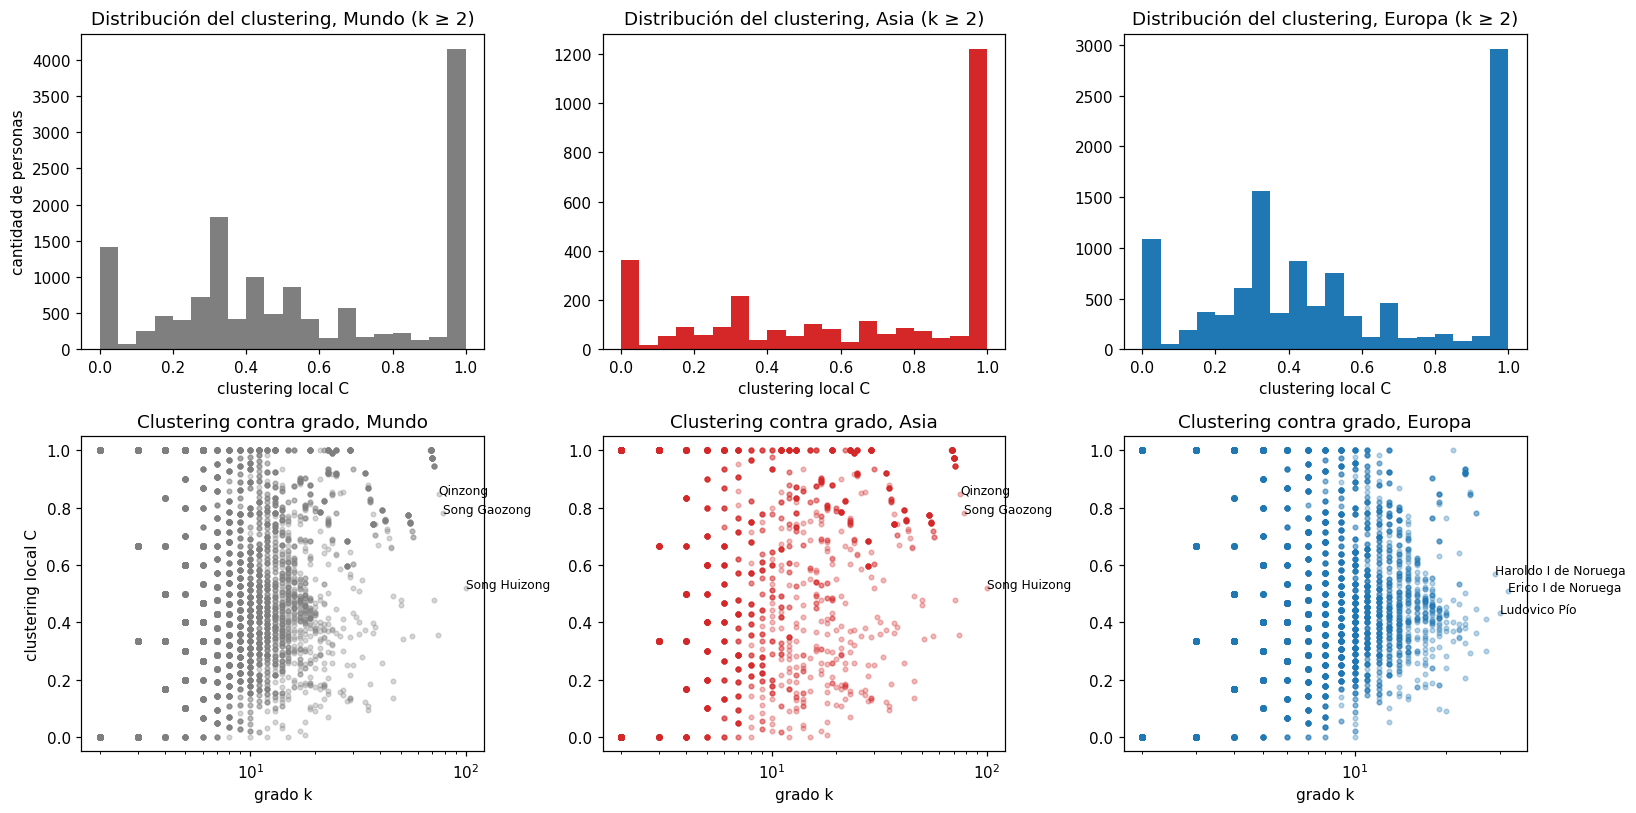

In [39]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5))
for j, (region, G) in enumerate(redes.items()):
    C, k = clustering[region], dict(G.degree())
    con_vecinos = [v for v in G if k[v] >= 2]
    axs[0, j].hist([C[v] for v in con_vecinos], bins=20, color=COLORES[region])
    axs[0, j].set(xlabel="clustering local C", title=f"Distribución del clustering, {region} (k ≥ 2)")
    axs[1, j].semilogx([k[v] for v in con_vecinos], [C[v] for v in con_vecinos], "o", ms=3, alpha=0.3, color=COLORES[region])
    for v in sorted(G, key=G.degree, reverse=True)[:3]:
        axs[1, j].annotate(nombre(G, v), (k[v], C[v]), fontsize=8)
    axs[1, j].set(xlabel="grado k", title=f"Clustering contra grado, {region}")
axs[0, 0].set_ylabel("cantidad de personas"); axs[1, 0].set_ylabel("clustering local C")
plt.tight_layout(); plt.show()

A diferencia de una red social típica, acá la **transitividad es mayor que el clustering medio**, sobre todo en Asia. Los nodos de grado más alto son en buena parte miembros de grupos enormes de hermanos (por ejemplo, las decenas de hijos de Song Huizong), que forman cliques con muchísimos triángulos; como la transitividad pesa más a los nodos de grado alto, sube. El clustering medio, en cambio, lo bajan las miles de personas con $C = 0$ (incluidas las de grado 0 o 1, para las que networkx define $C = 0$).

✏️ ¿Qué personas con 10 o más vínculos tienen $C = 1$? Pista: `[nombre(mundo, v) for v in mundo if clustering["Mundo"][v] == 1 and mundo.degree(v) >= 10]`.

## 9. Medidas de centralidad

¿Quién es la persona más importante de la red? Depende de qué entendamos por importante:

| Medida | Idea | networkx |
|---|---|---|
| Grado | Cuántos vínculos tiene | `degree_centrality` |
| Closeness | Qué tan cerca está, en promedio, de todos los demás: $1/\langle d_{ij}\rangle_j$ | `closeness_centrality` |
| Betweenness | Qué fracción de los caminos más cortos pasan por ella | `betweenness_centrality` |
| Eigenvector | Es importante si está conectada a nodos importantes | `eigenvector_centrality` |
| PageRank | Probabilidad de estar en el nodo en una caminata aleatoria con saltos | `pagerank` |

Las calculamos sobre la componente gigante de cada red. La closeness ya la tenemos exacta de la sección 6. La betweenness exacta requiere un BFS desde cada nodo con más trabajo por paso, así que en las redes grandes la **estimamos** con `k = MUESTRA_BETWEENNESS` nodos de origen elegidos al azar (Asia, que es chica, va exacta).

In [40]:
MUESTRA_BETWEENNESS = 500    # ✏️ más grande = estimación más precisa pero más lenta

def centralidades(Gg, closeness):
    k = None if Gg.number_of_nodes() <= 2 * MUESTRA_BETWEENNESS else MUESTRA_BETWEENNESS
    return pd.DataFrame({
        "persona": {v: nombre(Gg, v) for v in Gg},
        "grado": dict(Gg.degree()),
        "closeness": closeness,
        "betweenness": nx.betweenness_centrality(Gg, k=k, seed=SEMILLA),
        "eigenvector": nx.eigenvector_centrality_numpy(Gg),
        "pagerank": nx.pagerank(Gg, weight="weight"),
    })

cent = {region: centralidades(Gg, distancias[region]["closeness"]) for region, Gg in gigantes.items()}

def top_por_medida(c, n=10):
    medidas = ["grado", "closeness", "betweenness", "eigenvector", "pagerank"]
    return pd.DataFrame({m: c.sort_values(m, ascending=False)["persona"].values[:n] for m in medidas},
                        index=range(1, n + 1))

for region in REGIONES:
    print(f"=== {region}")
    display(top_por_medida(cent[region]))

=== Mundo


,grado,closeness,betweenness,eigenvector,pagerank
1,Erico I de Noruega,Felipe II de Francia,Abaqa,Erico I de Noruega,Ali Ibn Abi Talib
2,Ludovico Pío,Federico II Hohenstaufen,María Paleóloga,Haroldo I de Noruega,Mahoma
3,Haroldo I de Noruega,Matilde Plantagenet,Hulagu,Ålov Haraldsdotter,Muawiya ibn Abi Sufyan
4,Gengis Kan,María de Francia,Andrónico II Paleólogo,Rørek Haraldsson,Gengis Kan
5,Alfonso X de Castilla y de León,Leonor Plantagenet,Ludovico Pío,Sigtrygg Haraldsson,Harún al-Rashid
6,Carlomagno,Alix de Francia,Carlomagno,Torgils Haraldsson,Kublai Kan
7,Kublai Kan,Juan I de Inglaterra,Juan I de Portugal,Frode Haraldsson,Ubayd Allah ibn Ziyad
8,Fernando III de Castilla,Violante de Hungría,Carlos el Temerario,Bjørn Farmann,Abd al-Malik
9,Ring Haraldsson,Andrés II de Hungría,Federico II Hohenstaufen,Ring Haraldsson,Abaqa
10,Bjørn Farmann,Luis VII de Francia,Pipino el Breve,Guttorm Haraldsson,Vladimiro I de Kiev


=== Asia


,grado,closeness,betweenness,eigenvector,pagerank
1,Emperador Saga,Emperador Murakami,Emperador Murakami,Emperador Saga,Emperador Kanmu
2,Emperador Kanmu,Emperador Reizei,Emperador Kōkō,Emperador Heizei,Emperador Saga
3,Emperador Murakami,Emperador En'yū,Emperador Shirakawa,Emperador Junna,Emperador Seiwa
4,Emperador Daigo,Emperador Sanjō,Ninmyō,Koshi-naishinnō,Emperador Montoku
5,Emperador Montoku,Emperador Daigo,Emperador Daigo,Ito-naishinnō,Ninmyō
6,Ninmyō,Emperador Ichijō,Emperador Go-Sanjō,Kaya-shinnō,Emperador Daigo
7,Emperador Seiwa,Emperador Go-Suzaku,Emperador Saga,Kazurahara-shinnō,Emperador Kōkō
8,Emperador Heizei,Princess Teishi,Emperador Kanmu,Fujii-shinnō,Emperador Murakami
9,Emperador Junna,Yasuko-naishinnō,Emperador Uda,Asahara-naishinnō,Emperador Uda
10,Emperatriz Genmei,Emperador Uda,Emperador Takakura,Kōzu-naishinnō,Emperador Go-Daigo


=== Europa


,grado,closeness,betweenness,eigenvector,pagerank
1,Erico I de Noruega,Matilde Plantagenet,Juan I de Portugal,Erico I de Noruega,Vladimiro I de Kiev
2,Ludovico Pío,Felipe II de Francia,Ludovico Pío,Haroldo I de Noruega,Estorre Visconti
3,Haroldo I de Noruega,Alix de Francia,Carlomagno,Ålov Haraldsdotter,Alfonso IX de León
4,Carlomagno,Leonor Plantagenet,Pipino el Breve,Sigtrygg Haraldsson,Ambrogio Visconti
5,Alfonso X de Castilla y de León,María de Francia,Juan I de Inglaterra,Rørek Haraldsson,Haroldo I de Noruega
6,Fernando III de Castilla,Juan I de Inglaterra,Pedro I de Portugal,Torgils Haraldsson,Carlomagno
7,Ring Haraldsson,Federico II Hohenstaufen,Carlos Martel,Frode Haraldsson,Francisco I Sforza
8,Leonor Plantagenet,Enrique II de Brabante,Carlos el Temerario,Bjørn Farmann,Svend II de Dinamarca
9,Bjørn Farmann,Leonor de Aquitania,Federico II Hohenstaufen,Ring Haraldsson,Teresa Pires I de Bragança
10,Guttorm Haraldsson,Luis VII de Francia,"Guy II, Count of Blois",Guttorm Haraldsson,"John I, Marquis of Namur"


Los rankings se parecen, pero no son iguales. Fíjense en quiénes tienen grado moderado pero betweenness alta: son las personas que unen dinastías que de otro modo estarían lejos (típicamente por matrimonios entre casas). En el Mundo, los primeros puestos de betweenness son justamente el puente entre Europa y Asia (los Paleólogos y los iljanes mongoles). La centralidad de autovector, en cambio, se concentra en el grupo de hermanos más grande de la componente (en Europa, los hijos de Haroldo I de Noruega).

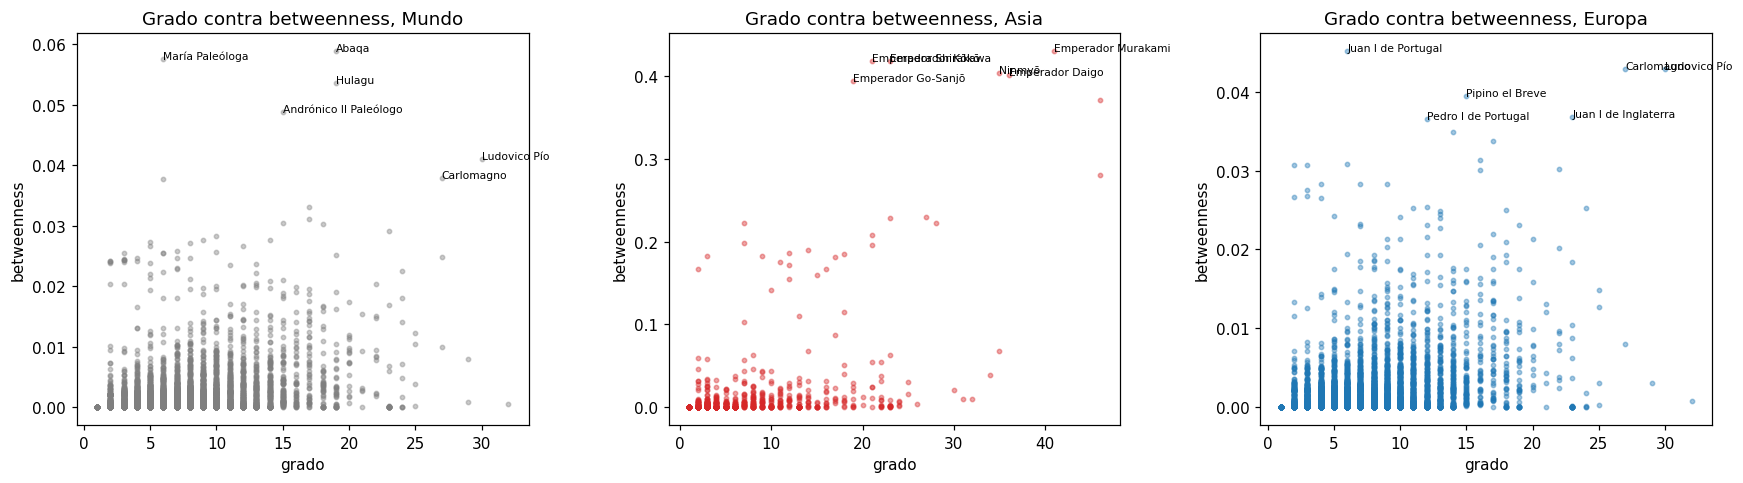

In [41]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, region in zip(axs, REGIONES):
    c = cent[region]
    ax.scatter(c["grado"], c["betweenness"], s=8, alpha=0.4, color=COLORES[region])
    for v in c.sort_values("betweenness", ascending=False).index[:6]:
        ax.annotate(c.loc[v, "persona"], (c.loc[v, "grado"], c.loc[v, "betweenness"]), fontsize=7)
    ax.set(xlabel="grado", ylabel="betweenness", title=f"Grado contra betweenness, {region}")
plt.tight_layout(); plt.show()

¿Qué tan parecidas son las medidas entre sí? La correlación de Spearman compara los **rankings** (1 = mismo orden).

In [42]:
pd.concat({region: cent[region].drop(columns="persona").corr(method="spearman") for region in REGIONES}, axis=0).round(2)

grado  closeness  betweenness  eigenvector  pagerank
Mundo  grado         1.00       0.43         0.75         0.25      0.85
       closeness     0.43       1.00         0.37         0.48      0.21
       betweenness   0.75       0.37         1.00         0.20      0.78
       eigenvector   0.25       0.48         0.20         1.00      0.13
       pagerank      0.85       0.21         0.78         0.13      1.00
Asia   grado         1.00       0.21         0.74         0.14      0.89
       closeness     0.21       1.00         0.16         0.55      0.11
       betweenness   0.74       0.16         1.00         0.07      0.80
       eigenvector   0.14       0.55         0.07         1.00      0.03
       pagerank      0.89       0.11         0.80         0.03      1.00
Europa grado         1.00       0.43         0.75         0.27      0.85
       closeness     0.43       1.00         0.37         0.46      0.20
       betweenness   0.75       0.37         1.00         0.20      0.78
       eigenvector   0.27       0.46         0.20         1.00      0.13
       pagerank      0.85       0.20         0.78         0.13      1.00

### ✏️ Para explorar
- ¿Quién tiene la mayor betweenness en el Mundo? ¿Es de Asia o de Europa? ¿Por qué ocupa ese lugar?
- Calculen la betweenness usando los pesos: `nx.betweenness_centrality(gigantes["Asia"], weight="distancia")`. ¿Cambia el ranking?
- Busquen dónde quedan sus personas favoritas: `cent["Europa"].sort_values("betweenness", ascending=False).reset_index().query("persona == 'Carlomagno'")`.

## 10. ¿Con quién se vincula cada uno? Asortatividad

La **asortatividad** mide si los nodos tienden a conectarse con nodos parecidos (valor positivo) o distintos (negativo):

- Por **grado**: ¿los hubs se vinculan con hubs?
- Por **continente** (sólo tiene sentido en el Mundo): ¿los vínculos quedan dentro del mismo continente?
- Por **casa**: ¿los vínculos quedan dentro de la misma dinastía? (Sólo entre personas con casa registrada.)

In [43]:
def con_casa(G):
    return G.subgraph([v for v in G if G.nodes[v]["casa"]])

filas = {}
for region, G in redes.items():
    filas[region] = {"por grado": nx.degree_assortativity_coefficient(G),
                     "por casa": nx.attribute_assortativity_coefficient(con_casa(G), "casa")}
filas["Mundo"]["por continente"] = nx.attribute_assortativity_coefficient(mundo, "continente")
display(pd.DataFrame(filas).T.round(3))
print("Ojo: los cliques de hermanos inflan la asortatividad por grado (todos los hermanos tienen grados parecidos).\n")

pares_continente = Counter(tuple(sorted((mundo.nodes[u]["continente"], mundo.nodes[v]["continente"])))
                           for u, v in mundo.edges())
print("Vínculos del Mundo según el continente de cada extremo:")
pd.Series(pares_continente, name="vínculos").rename_axis(["continente 1", "continente 2"]).to_frame()

,por grado,por casa,por continente
Mundo,0.861,0.793,0.959
Asia,0.832,0.893,NaN
Europa,0.480,0.687,NaN


Ojo: los cliques de hermanos inflan la asortatividad por grado (todos los hermanos tienen grados parecidos).

Vínculos del Mundo según el continente de cada extremo:


vínculos
continente 1 continente 2          
Europa       Europa           31197
Asia         Europa             835
             Asia             14728

In [44]:
# ¿Quiénes cruzan continentes? Las personas con más vínculos con el otro continente
cruces = pd.Series({v: sum(1 for w in mundo[v] if mundo.nodes[w]["continente"] != mundo.nodes[v]["continente"])
                    for v in mundo})
cruces = cruces[cruces > 0].sort_values(ascending=False)
pd.DataFrame({"persona": [nombre(mundo, v) for v in cruces.index[:10]],
              "continente": [mundo.nodes[v]["continente"] for v in cruces.index[:10]],
              "casa": [mundo.nodes[v]["casa"] for v in cruces.index[:10]],
              "ubicación": [nodos.set_index("Id").loc[v, "ubicacion"] for v in cruces.index[:10]],
              "vínculos con el otro continente": cruces.values[:10]})

,persona,continente,casa,ubicación,vínculos con el otro continente
0,Juana de Acre,Asia,,Acre,17
1,Blanca de Francia,Asia,Casa de los Capetos,Jaffa,14
2,Ana de Lusignan,Asia,,Nicosia,13
3,Pere I d'Alençon,Asia,,Atlit,12
4,Pedro II de Saboya,Asia,,Susa,12
5,Konstantín de Vladímir,Asia,,Mermer,10
6,"Elisabeth of Brandenburg, Duchess of Brzeg-Leg...",Asia,,NaN,10
7,Inés de Châtillon,Asia,,Principado de Antioquía,10
8,María de Artois,Asia,House of Artois,El Mansurá,10
9,Roberto II de Artois,Asia,House of Artois,El Mansurá,9


Muchas de estas personas son nobles europeos de los estados cruzados (Acre, Jaffa, Chipre), a quienes la columna `continente` asigna a Asia por su `ubicacion`. Vale la pena revisar algunos casos: por ejemplo, Pedro II de Saboya figura en Asia por la ubicación "Susa", que probablemente es la Susa del Piamonte y no la de Persia. Estos casos afectan directamente a las redes de Asia y Europa.

## 11. Explorar todo en Gephi

[Gephi](https://gephi.org/) es un programa de escritorio para explorar redes visualmente (no corre dentro de Colab). Exportamos cada red como archivo **GEXF** con todas las medidas que calculamos como atributos de los nodos. Las medidas que sólo existen en la componente gigante (excentricidad, closeness, betweenness, ...) quedan en `-1` para las personas fuera de ella; en Gephi se pueden filtrar con `en_gigante`.

In [45]:
CARPETA_GEXF = Path("gexf")
CARPETA_GEXF.mkdir(exist_ok=True)

def exportar_gexf(G, Gg, c, dist, archivo):
    # GEXF exige que cada atributo tenga un único tipo: convertimos a int, float o str
    H = nx.Graph()
    for v, d in G.nodes(data=True):
        H.add_node(v, label=d["label"], casa=d["casa"], titulo=d["titulo"], continente=d["continente"],
                   anio=int(d["anio"]), sexo=d["sexo"], en_gigante=v in Gg)
    for u, v, d in G.edges(data=True):
        H.add_edge(u, v, weight=float(d["weight"]), tipo=d["tipo"], sospechosa=bool(d["sospechosa"]))
    nx.set_node_attributes(H, {v: int(k) for v, k in G.degree()}, "grado")
    nx.set_node_attributes(H, {v: int(s) for v, s in G.degree(weight="weight")}, "fuerza")
    nx.set_node_attributes(H, {v: float(x) for v, x in nx.clustering(G).items()}, "clustering")
    exc = dist["excentricidad"]
    nx.set_node_attributes(H, {v: int(exc.get(v, -1)) for v in G}, "excentricidad")
    for col in ["closeness", "betweenness", "eigenvector", "pagerank"]:
        nx.set_node_attributes(H, {v: float(c[col].get(v, -1.0)) for v in G}, col)
    nx.write_gexf(H, archivo)
    print("Guardado:", archivo)

for region in REGIONES:
    exportar_gexf(redes[region], gigantes[region], cent[region], distancias[region],
                  CARPETA_GEXF / f"dinastias_{region.lower()}.gexf")

try:
    from google.colab import files
    for region in REGIONES:
        files.download(str(CARPETA_GEXF / f"dinastias_{region.lower()}.gexf"))
except ImportError:
    print(f"No estamos en Colab: los archivos quedaron en {CARPETA_GEXF.resolve()}")

Guardado: gexf\dinastias_mundo.gexf


Guardado: gexf\dinastias_asia.gexf


Guardado: gexf\dinastias_europa.gexf
No estamos en Colab: los archivos quedaron en C:\Users\HP\Tomas\Ciencia de datos\2do año\Redes Complejas\Redes-Complejas\colabs-analisis\gexf


### Paso a paso

1. **Abrir** `dinastias_mundo.gexf` (*File → Open*), como grafo *Undirected*.
2. **Layout**: en el panel *Layout*, elegir *ForceAtlas 2* (con 18.000 nodos conviene activar *Approximate Repulsion*), marcar *Prevent Overlap*, *Run* y, cuando se estabilice, *Stop*.
3. **Tamaño por grado**: *Appearance → Nodes → Size → Ranking → grado* (por ejemplo, de 2 a 40) y *Apply*.
4. **Color por continente**: *Appearance → Nodes → Color → Partition → continente* y *Apply*. Después prueben *Ranking → betweenness*.
5. **Etiquetas**: activarlas con el ícono "T" de la barra inferior de la vista *Graph*.
6. **Exportar la imagen**: pestaña *Preview*, *Refresh*, *Export* (PNG, SVG o PDF).

### ✏️ Tareas en Gephi

1. **Desafío en Gephi.** Con la herramienta *Shortest path* (en la barra de herramientas a la izquierda de la vista *Graph*), hagan clic en dos personas: Gephi resalta el camino más corto. Busquen a ojo las dos más lejanas. ¿Llegan al diámetro que calculamos en la sección 6?
2. **Distintos layouts.** Prueben *Fruchterman Reingold* y *Yifan Hu* además de *ForceAtlas 2*. ¿Con cuál se distinguen mejor Asia y Europa?
3. **Las medidas de Gephi.** En *Statistics*, corran *Network Diameter* y *Avg. Clustering Coefficient*. ¿Coinciden con lo que calculamos acá? (Recuerden que nosotros medimos el diámetro sobre la componente gigante.)
4. **Conectividad.** En *Filters → Attributes → Range → weight*, quédense con las aristas de peso 3 (padre/madre) y corran *Statistics → Connected Components*. Coloreen por componente. ¿Coinciden con la sección 7.1?
5. **Robustez.** En *Data Laboratory*, borren a la persona con mayor betweenness y vuelvan a correr *Connected Components*. ¿Qué parte de la red queda separada?
6. Repitan con `dinastias_asia.gexf` y `dinastias_europa.gexf`.

## 12. Para seguir

1. Elijan tres personas y armen una tabla con su grado, fuerza, clustering, excentricidad y betweenness en la red de su continente y en la del Mundo. ¿Cambia su papel cuando se agregan los vínculos con el otro continente?
2. ¿Cuál es el diámetro de cada red si se usan los pesos? `nx.diameter(gigantes["Asia"], weight="distancia")` (en la red del Mundo tarda mucho: prueben con Asia). ¿Qué par queda más lejos?
3. ¿Cuántas personas hay que sacar, empezando por las de mayor grado, para que la componente gigante tenga menos de la mitad de las personas? ¿Y si se sacan en orden de betweenness (`cent[region]["betweenness"]`)?
4. Repitan el análisis con `EXCLUIR_SOSPECHOSAS = True` (sección 2.1). ¿Cambia alguna medida?
5. Usen la columna `anio` para cortar la red por siglo. ¿Cómo evolucionan el tamaño de la componente gigante y los vínculos entre Asia y Europa?